# Strategia value-growth con γ: S&P 500 e universo completo (NYSE, AMEX, NASDAQ)

**Regole:**
- Ordinamento mensile per book-to-market; long terzile value (B/M alto), short terzile growth (B/M basso); pesi per capitalizzazione; detenzione un mese.
- γ composito fisso (pendenza curva, variazione 2 anni, variazione inflazione attesa), limitato tra −1 e +1, dati del mese precedente.
- Variante: γ da regressione rolling a 36 mesi (pendenza e variazione 2 anni).
- Universi: membri S&P 500; tutte le azioni ordinarie USA su NYSE, AMEX, NASDAQ (terzili sull'universo e, come verifica, con breakpoint NYSE).
- Periodi: 1990-2009, 2010-21 (stima), 2022-25 (fuori campione), dal 1995.

## 1. Librerie e funzioni di base

In [1]:
import zipfile
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

def leggi_zip(path, **kw):
    with zipfile.ZipFile(path) as z:
        return pd.read_csv(z.open(z.namelist()[0]), **kw)

def hac(y, X):
    return sm.OLS(y, sm.add_constant(X)).fit(cov_type="HAC", cov_kwds={"maxlags": 6})

def sharpe(r):
    return r.mean() / r.std() * np.sqrt(12)

def drawdown_max(r):
    cum = (1 + r).cumprod()
    return (cum / cum.cummax() - 1).min()

print("Pronto")

Pronto


## 2. Dati CRSP mensili e definizione degli universi

- Rendimenti e capitalizzazioni mensili da CRSP (i rendimenti includono già il delisting).
- **Universo completo:** azioni ordinarie (`sharetype = NS`, `securitytype = EQTY`, `securitysubtype = COM`),
  società USA (`usincflg = Y`, `issuertype` ACOR/CORP), borsa principale NYSE (N), AMEX (A) o NASDAQ (Q),
  verificato mese per mese con le date di validità dell'anagrafica.
- **S&P 500:** membri mese per mese; dal 2023 si usano i membri di fine 2022.

In [2]:
# --- CRSP mensile
crsp = leggi_zip("Data/jhvzegjsguw3gw3k_csv.zip", usecols=["PERMNO", "MthCalDt", "MthCap", "MthRet", "MthPrc"])
crsp["MthCalDt"] = pd.to_datetime(crsp["MthCalDt"])
crsp["mese"] = crsp["MthCalDt"].dt.to_period("M")
crsp["MthRet"] = pd.to_numeric(crsp["MthRet"], errors="coerce")
crsp = crsp.dropna(subset=["MthCap"]).drop_duplicates(["PERMNO", "mese"])

# --- anagrafica titoli: controllo dei codici
hdr = leggi_zip("Data/honhxqxgerziffrf.csv.zip")
hdr.columns = hdr.columns.str.lower()
for c in ["primaryexch", "sharetype", "securitytype", "securitysubtype", "usincflg", "issuertype"]:
    print(c, hdr[c].value_counts().head(6).to_dict())

# --- azioni ordinarie USA su NYSE / AMEX / NASDAQ, valide mese per mese
hdr["inizio"] = pd.to_datetime(hdr["secinfostartdt"], errors="coerce")
hdr["fine"] = pd.to_datetime(hdr["secinfoenddt"], errors="coerce").fillna(pd.Timestamp("2099-12-31"))
comuni = hdr[(hdr["sharetype"] == "NS") & (hdr["securitytype"] == "EQTY") & (hdr["securitysubtype"] == "COM")
             & (hdr["usincflg"] == "Y") & hdr["issuertype"].isin(["ACOR", "CORP"])
             & hdr["primaryexch"].isin(["N", "A", "Q"])]
u = crsp[["PERMNO", "mese", "MthCalDt"]].merge(
        comuni[["permno", "inizio", "fine", "primaryexch"]].rename(columns={"permno": "PERMNO"}), on="PERMNO")
u = u[(u["MthCalDt"] >= u["inizio"]) & (u["MthCalDt"] <= u["fine"])].drop_duplicates(["PERMNO", "mese"])
crsp = crsp.merge(u[["PERMNO", "mese", "primaryexch"]], on=["PERMNO", "mese"], how="left")
crsp["tutte"] = crsp["primaryexch"].notna()

# --- membri S&P 500 mese per mese
ch = pd.read_csv("Data/sp500_constituent_changes.csv", parse_dates=["SP500 Start", "SP500 End"])
memb = ch[["PERMNO", "SP500 Start", "SP500 End"]].copy()
memb.loc[memb["SP500 End"] == "2022-12-30", "SP500 End"] = pd.Timestamp("2026-12-31")
sp = crsp[["PERMNO", "mese", "MthCalDt"]].merge(memb, on="PERMNO")
sp = sp[(sp["MthCalDt"] >= sp["SP500 Start"]) & (sp["MthCalDt"] <= sp["SP500 End"])]
chiave = pd.MultiIndex.from_frame(crsp[["PERMNO", "mese"]])
crsp["sp500"] = chiave.isin(pd.MultiIndex.from_frame(sp[["PERMNO", "mese"]]))

print("\nTitoli per mese in media | universo completo:", round(crsp[crsp["tutte"]].groupby("mese").size().mean()),
      "| S&P 500:", round(crsp[crsp["sp500"]].groupby("mese").size().mean()))
print("Periodo CRSP:", crsp["mese"].min(), "→", crsp["mese"].max())

primaryexch {'Q': 91584, 'N': 39760, 'X': 31810, 'A': 14492, 'R': 10035, 'B': 3366}
sharetype {'NS': 148851, 'AD': 6696, 'SB': 4094, 'UG': 1528, 'CE': 46}
securitytype {'EQTY': 136698, 'FUND': 24436, 'DERV': 81}
securitysubtype {'COM': 136698, 'UNK': 29833, 'ETF': 17949, 'CEF': 6487, 'ATR': 81}
usincflg {'Y': 143627, 'N': 47421}
issuertype {'CORP': 128933, 'ACOR': 58394, 'REIT': 3721}

Titoli per mese in media | universo completo: 5017 | S&P 500: 452
Periodo CRSP: 1975-01 → 2025-12


### Controllo: perché in media 452 membri S&P 500 invece di 500?

1. Numero di membri trovati in CRSP mese per mese (grafico).
2. Confronto anno per anno: membri secondo il file delle composizioni contro membri trovati in CRSP.
3. In un mese di esempio: quali membri mancano, e se mancano del tutto dal file CRSP o ci sono ma senza capitalizzazione.

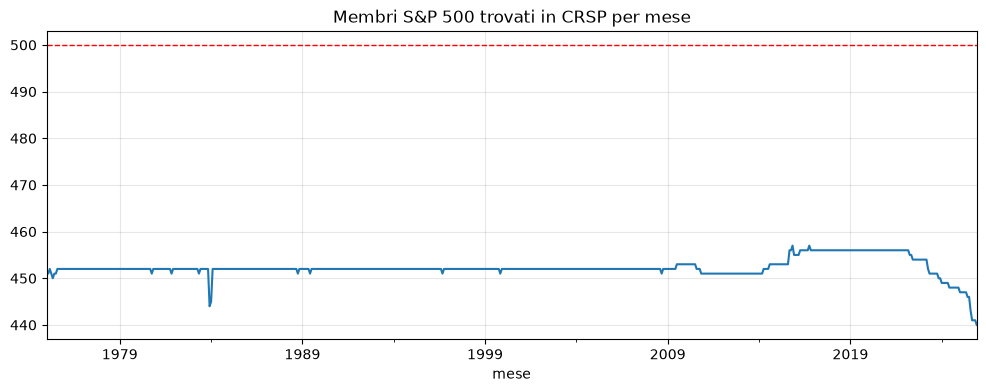

Media per anno:


,Membri nel file,Trovati in CRSP,Mancanti
1975,633.0,451.0,182.0
1976,649.0,452.0,197.0
1977,659.0,452.0,207.0
1978,662.0,452.0,210.0
1979,667.0,452.0,215.0
1980,669.0,452.0,217.0
1981,673.0,452.0,221.0
1982,678.0,452.0,226.0
1983,682.0,451.0,230.0
1984,687.0,451.0,236.0



2010-06: membri nel file 453, trovati in CRSP 453, mancanti 0
 - nel file CRSP grezzo quel mese ma con MthCap mancante: 0
 - assenti dal file CRSP grezzo quel mese: 0
 - assenti dal file CRSP grezzo in tutti i mesi: 0
Esempi di PERMNO mancanti: []


In [24]:
# ---------- 1. membri S&P 500 trovati in CRSP, mese per mese ----------
n_sp = crsp[crsp["sp500"]].groupby("mese").size()
ax = n_sp.plot(figsize=(12, 4), title="Membri S&P 500 trovati in CRSP per mese")
ax.axhline(500, color="red", ls="--", lw=1); ax.grid(alpha=0.3); plt.show()

# ---------- 2. membri attesi dal file, indipendentemente da CRSP ----------
mesi_c = pd.period_range(crsp["mese"].min(), crsp["mese"].max(), freq="M")
fine_c = mesi_c.to_timestamp(how="end").normalize()
attesi = pd.Series([((memb["SP500 Start"] <= d) & (memb["SP500 End"] >= d)).sum() for d in fine_c], index=mesi_c)
confronto = pd.DataFrame({"Membri nel file": attesi, "Trovati in CRSP": n_sp}).fillna(0)
confronto["Mancanti"] = confronto["Membri nel file"] - confronto["Trovati in CRSP"]
print("Media per anno:")
display(confronto.groupby(confronto.index.year).mean().round(0))

# ---------- 3. un mese di esempio: chi manca e perché ----------
MESE = pd.Period("2010-06", "M")                       # cambia mese se vuoi
d = MESE.to_timestamp(how="end").normalize()
attivi = memb.loc[(memb["SP500 Start"] <= d) & (memb["SP500 End"] >= d), "PERMNO"].drop_duplicates()
in_crsp = crsp.loc[crsp["mese"] == MESE, "PERMNO"]
mancanti = attivi[~attivi.isin(in_crsp)]
grezzo = leggi_zip("Data/jhvzegjsguw3gw3k_csv.zip", usecols=["PERMNO", "MthCalDt", "MthCap"])
grezzo["mese"] = pd.to_datetime(grezzo["MthCalDt"]).dt.to_period("M")
g_m = grezzo[grezzo["mese"] == MESE]
print(f"\n{MESE}: membri nel file {len(attivi)}, trovati in CRSP {attivi.isin(in_crsp).sum()}, mancanti {len(mancanti)}")
print(" - nel file CRSP grezzo quel mese ma con MthCap mancante:",
      mancanti.isin(g_m.loc[g_m["MthCap"].isna(), "PERMNO"]).sum())
print(" - assenti dal file CRSP grezzo quel mese:", (~mancanti.isin(g_m["PERMNO"])).sum())
print(" - assenti dal file CRSP grezzo in tutti i mesi:", (~mancanti.isin(grezzo["PERMNO"])).sum())
print("Esempi di PERMNO mancanti:", mancanti.head(10).tolist())

### Controllo: il flag S&P 500 segue davvero l'indice?

Se il flag è corretto, ogni anno devono entrare e uscire circa 20–30 titoli (le modifiche reali dell'indice),
e in 50 anni devono passare da lì molto più di 500 titoli diversi.
Se invece i titoli sono quasi sempre gli stessi, il flag riproduce la composizione di un solo momento: bias di sopravvivenza.

In [25]:
# ---------- il file delle composizioni ----------
print("Righe nel file:", len(memb), "| PERMNO diversi:", memb["PERMNO"].nunique(),
      "| righe duplicate identiche:", memb.duplicated().sum())
print("Data di inizio più vecchia:", memb["SP500 Start"].min(), "| più recente:", memb["SP500 Start"].max())
display(memb.sort_values("PERMNO").head(10))

# ---------- il flag in CRSP: quanti titoli diversi e quanto cambia ogni anno ----------
flag = crsp.loc[crsp["sp500"], ["PERMNO", "mese"]]
print("\nPERMNO diversi con flag S&P 500 in tutto il campione:", flag["PERMNO"].nunique())
per_anno = flag.groupby(flag["mese"].dt.year)["PERMNO"].apply(set)
cambi = pd.DataFrame({"Titoli nell'anno": per_anno.apply(len),
                      "Entrati rispetto all'anno prima": [len(per_anno.iloc[i] - per_anno.iloc[i - 1]) if i else np.nan
                                                         for i in range(len(per_anno))]},
                     index=per_anno.index)
display(cambi.T)

Righe nel file: 2848 | PERMNO diversi: 1806 | righe duplicate identiche: 959
Data di inizio più vecchia: 1925-12-31 00:00:00 | più recente: 2022-12-22 00:00:00


,PERMNO,SP500 Start,SP500 End
985,10006,1957-03-01,1984-07-18
362,10030,1957-03-01,1969-01-08
1327,10057,1957-03-01,1992-07-02
1318,10078,1992-08-20,2010-01-28
2315,10078,1992-08-20,2010-01-28
566,10102,1957-03-01,1975-02-05
1233,10104,1989-08-03,2026-12-31
1369,10107,1994-06-07,2026-12-31
2018,10108,2002-07-22,2005-08-11
1906,10108,2002-07-22,2005-08-11



PERMNO diversi con flag S&P 500 in tutto il campione: 1553


mese,1975,1976,1977,1978,1979,1980,1981,1982,1983,1984,1985,1986,1987,1988,1989,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Titoli nell'anno,470.0,508.0,459.0,465.0,466.0,467.0,472.0,479.0,464.0,482.0,477.0,477.0,478.0,477.0,480.0,...,469.0,468.0,469.0,466.0,479.0,483.0,482.0,479.0,476.0,472.0,473.0,472.0,454.0,449.0,447.0
Entrati rispetto all'anno prima,NaN,60.0,8.0,13.0,15.0,16.0,20.0,28.0,13.0,38.0,28.0,28.0,27.0,25.0,30.0,...,20.0,18.0,19.0,16.0,28.0,30.0,28.0,24.0,22.0,17.0,19.0,16.0,0.0,0.0,0.0


### Membri S&P 500 senza duplicati

Il file delle composizioni contiene righe duplicate identiche: le tolgo e ricalcolo quanti membri ci sono ogni mese
nel file e quanti ne troviamo in CRSP.

In [27]:
memb_u = memb.drop_duplicates()
attesi_u = pd.Series([((memb_u["SP500 Start"] <= d) & (memb_u["SP500 End"] >= d)).sum() for d in fine_c], index=mesi_c)
conf_u = pd.DataFrame({"Membri nel file": attesi_u, "Trovati in CRSP": n_sp}).fillna(0)
conf_u["Mancanti"] = conf_u["Membri nel file"] - conf_u["Trovati in CRSP"]
display(conf_u.groupby(conf_u.index.year).mean().round(0).T)

quota = crsp[crsp["sp500"]].groupby("mese")["MthCap"].sum() / crsp[crsp["tutte"]].groupby("mese")["MthCap"].sum()
print(quota.groupby(quota.index.year).mean().round(2).to_string())

,1975,1976,1977,1978,1979,1980,1981,1982,1983,1984,1985,1986,1987,1988,1989,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Membri nel file,452.0,452.0,452.0,452.0,452.0,452.0,452.0,452.0,452.0,452.0,452.0,452.0,452.0,452.0,452.0,...,451.0,451.0,451.0,452.0,454.0,456.0,456.0,456.0,456.0,456.0,456.0,455.0,454.0,454.0,454.0
Trovati in CRSP,451.0,452.0,452.0,452.0,452.0,452.0,452.0,452.0,451.0,451.0,452.0,452.0,452.0,452.0,452.0,...,451.0,451.0,451.0,452.0,454.0,456.0,456.0,456.0,456.0,456.0,456.0,455.0,452.0,448.0,444.0
Mancanti,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,...,-0.0,-0.0,-0.0,0.0,0.0,-0.0,0.0,-0.0,-0.0,0.0,0.0,0.0,2.0,6.0,10.0


mese
1975    0.50
1976    0.52
1977    0.52
1978    0.50
1979    0.51
1980    0.53
1981    0.53
1982    0.54
1983    0.52
1984    0.52
1985    0.52
1986    0.52
1987    0.54
1988    0.55
1989    0.56
1990    0.56
1991    0.54
1992    0.53
1993    0.53
1994    0.53
1995    0.54
1996    0.53
1997    0.55
1998    0.58
1999    0.62
2000    0.60
2001    0.62
2002    0.61
2003    0.60
2004    0.60
2005    0.59
2006    0.59
2007    0.59
2008    0.59
2009    0.61
2010    0.62
2011    0.62
2012    0.63
2013    0.64
2014    0.66
2015    0.69
2016    0.71
2017    0.72
2018    0.73
2019    0.74
2020    0.76
2021    0.75
2022    0.76
2023    0.77
2024    0.79
2025    0.78


## 3. Book-to-market e rendimento del mese successivo

- Book equity = `ceq` (Compustat annuale, formato industriale standard, consolidato), collegato a CRSP con la tabella CCM.
- Usato solo il bilancio chiuso da almeno 6 mesi e non più di 18 (nessun look-ahead); book equity negativo escluso.
- B/M = book equity / capitalizzazione a fine mese.

In [3]:
comp = leggi_zip("Data/rdmfynls1xcgmjjb.csv.zip", usecols=["gvkey", "datadate", "indfmt", "datafmt", "consol", "ceq"])
comp = comp[(comp["indfmt"] == "INDL") & (comp["datafmt"] == "STD") & (comp["consol"] == "C")].dropna(subset=["ceq"])
comp["datadate"] = pd.to_datetime(comp["datadate"])

lnk = leggi_zip("Data/kg7lz7q7gsbmphju_csv.zip")
lnk = lnk[lnk["LINKTYPE"].isin(["LU", "LC"]) & lnk["LINKPRIM"].isin(["P", "C"])].dropna(subset=["LPERMNO"])
lnk["LINKDT"] = pd.to_datetime(lnk["LINKDT"])
lnk["LINKENDDT"] = pd.to_datetime(lnk["LINKENDDT"], errors="coerce").fillna(pd.Timestamp("2099-12-31"))

book = comp.merge(lnk[["gvkey", "LPERMNO", "LINKDT", "LINKENDDT"]], on="gvkey")
book = book[(book["datadate"] >= book["LINKDT"]) & (book["datadate"] <= book["LINKENDDT"])]
book = book.rename(columns={"LPERMNO": "PERMNO"})[["PERMNO", "datadate", "ceq"]]
book["PERMNO"] = book["PERMNO"].astype(int)
book["disponibile"] = book["datadate"] + pd.DateOffset(months=6)
book = book.drop_duplicates(["PERMNO", "datadate"], keep="last").sort_values("disponibile")

crsp = crsp.sort_values("MthCalDt")
crsp = pd.merge_asof(crsp, book[["PERMNO", "disponibile", "ceq"]], left_on="MthCalDt", right_on="disponibile",
                     by="PERMNO", direction="backward", tolerance=pd.Timedelta(days=366))
crsp["BM"] = np.where(crsp["ceq"] > 0, crsp["ceq"] * 1000 / crsp["MthCap"], np.nan)

# rendimento del mese successivo, allineato al mese di formazione
succ = crsp[["PERMNO", "mese", "MthRet"]].rename(columns={"MthRet": "ret_next"})
succ["mese"] = succ["mese"] - 1
crsp = crsp.merge(succ, on=["PERMNO", "mese"], how="left")

print("Quota con B/M disponibile | universo completo:", round(crsp.loc[crsp["tutte"], "BM"].notna().mean(), 2),
      "| S&P 500:", round(crsp.loc[crsp["sp500"], "BM"].notna().mean(), 2))

Quota con B/M disponibile | universo completo: 0.82 | S&P 500: 0.95


## 4. Portafogli value-growth

Per ogni universo: terzili di B/M ogni mese, long value e short growth, pesi per capitalizzazione.
Per l'universo completo anche la versione con breakpoint calcolati sui soli titoli NYSE (metodo Fama-French).

In [4]:
def portafoglio_vg(df, breakpoint_nyse=False):
    df = df.dropna(subset=["BM", "ret_next", "MthCap"]).copy()
    base = df[df["primaryexch"] == "N"] if breakpoint_nyse else df
    bp = base.groupby("mese")["BM"].quantile([1/3, 2/3]).unstack()
    bp.columns = ["b33", "b67"]
    df = df.join(bp, on="mese")
    df["lato"] = np.select([df["BM"] <= df["b33"], df["BM"] > df["b67"]], ["growth", "value"], "medio")

    def gamba(lato):
        x = df[df["lato"] == lato]
        return (x["ret_next"] * x["MthCap"]).groupby(x["mese"]).sum() / x["MthCap"].groupby(x["mese"]).sum()

    ls = gamba("value") - gamba("growth")
    ls.index = ls.index + 1                                  # indice = mese di detenzione
    n = df[df["lato"] != "medio"].groupby(["mese", "lato"]).size().unstack().mean().round()
    return ls, n

universi = {"S&P 500": (crsp[crsp["sp500"]], False),
            "NYSE/AMEX/NASDAQ": (crsp[crsp["tutte"]], False),
            "NYSE/AMEX/NASDAQ (breakpoint NYSE)": (crsp[crsp["tutte"]], True)}
ls = {}
for nome, (df, bpn) in universi.items():
    ls[nome], n = portafoglio_vg(df, bpn)
    print(f"{nome}: titoli medi per lato -> growth {n['growth']:.0f}, value {n['value']:.0f}")

S&P 500: titoli medi per lato -> growth 144, value 144
NYSE/AMEX/NASDAQ: titoli medi per lato -> growth 1386, value 1386
NYSE/AMEX/NASDAQ (breakpoint NYSE): titoli medi per lato -> growth 1448, value 1579


## 5. Segnali sulle aspettative sui tassi e γ

- Fonte FRED: `T10Y2Y` (pendenza), `DGS2` (tasso 2 anni), `T10YIE` (inflazione attesa, dal 2003).
- Pendenza: scostamento dalla media dei 5 anni precedenti / deviazione standard. Variazioni a 3 mesi divise per la volatilità dei 5 anni precedenti.
- **γ composito fisso** = media dei tre segnali, limitata tra −1 e +1, ritardata di un mese.
- **γ rolling 36 mesi** = previsione di una regressione sui 36 mesi precedenti (pendenza e variazione 2 anni), divisa per la deviazione standard delle previsioni nella finestra, limitata tra −1 e +1. Stimata separatamente per ogni universo.

In [5]:
def fred(serie):
    df = pd.read_csv(f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={serie}")
    df.columns = ["data", serie]
    df["data"] = pd.to_datetime(df["data"])
    df[serie] = pd.to_numeric(df[serie], errors="coerce")
    s = df.dropna().set_index("data")[serie]
    return s.groupby(s.index.to_period("M")).last()

def z_livello(x):
    m = x.rolling(60, min_periods=36)
    return (x - m.mean()) / m.std()

def z_variazione(dx):
    return dx / dx.rolling(60, min_periods=36).std()

segnali = {"Pendenza curva": z_livello(fred("T10Y2Y")),
           "Variazione 2 anni (3m)": z_variazione(fred("DGS2").diff(3)),
           "Variazione infl. attesa (3m)": z_variazione(fred("T10YIE").diff(3))}
gamma_fisso = pd.concat(segnali, axis=1).mean(axis=1).clip(-1, 1).shift(1)

def gamma_rolling(y, W=36):
    X = pd.concat({k: segnali[k].shift(1) for k in ["Pendenza curva", "Variazione 2 anni (3m)"]}, axis=1)
    d = pd.concat([y.rename("y"), X], axis=1).dropna()
    out = {}
    for i in range(W, len(d)):
        train = d.iloc[i - W:i]
        Xtr = sm.add_constant(train[X.columns])
        b = sm.OLS(train["y"], Xtr).fit().params
        sd = (Xtr @ b).std()
        prev = b["const"] + (d.iloc[i][X.columns] * b[X.columns]).sum()
        out[d.index[i]] = np.clip(prev / sd, -1, 1) if sd > 0 else 0.0
    return pd.Series(out)

gamma_roll = {nome: gamma_rolling(s) for nome, s in ls.items()}
print("γ composito disponibile da:", gamma_fisso.dropna().index.min())

γ composito disponibile da: 1979-06


## 6. Risultati

Per ogni universo: rendimento mensile, Sharpe annualizzato, alfa (5 fattori Fama-French + momentum, Newey-West),
drawdown massimo, senza γ, con γ composito fisso e con γ rolling 36 mesi.
Poi il fuori campione anno per anno e il rendimento cumulato dal 2010.

Mesi  \
Universo                           Versione          Periodo           
S&P 500                            Senza γ           1990-2009   240   
                                                     2010-21     144   
                                                     2022-25      48   
                                                     Dal 1995    372   
                                   γ composito fisso 1990-2009   240   
                                                     2010-21     144   
                                                     2022-25      48   
                                                     Dal 1995    372   
                                   γ rolling 36 mesi 1990-2009   240   
                                                     2010-21     144   
                                                     2022-25      48   
                                                     Dal 1995    372   
NYSE/AMEX/NASDAQ                   Senza γ           1990-2009   240   
                                                     2010-21     144   
                                                     2022-25      48   
                                                     Dal 1995    372   
                                   γ composito fisso 1990-2009   240   
                                                     2010-21     144   
                                                     2022-25      48   
                                                     Dal 1995    372   
                                   γ rolling 36 mesi 1990-2009   240   
                                                     2010-21     144   
                                                     2022-25      48   
                                                     Dal 1995    372   
NYSE/AMEX/NASDAQ (breakpoint NYSE) Senza γ           1990-2009   240   
                                                     2010-21     144   
                                                     2022-25      48   
                                                     Dal 1995    372   
                                   γ composito fisso 1990-2009   240   
                                                     2010-21     144   
                                                     2022-25      48   
                                                     Dal 1995    372   
                                   γ rolling 36 mesi 1990-2009   240   
                                                     2010-21     144   
                                                     2022-25      48   
                                                     Dal 1995    372   

                                                               Rend. mensile  \
Universo                           Versione          Periodo                   
S&P 500                            Senza γ           1990-2009         0.18%   
                                                     2010-21          -0.47%   
                                                     2022-25          -0.20%   
                                                     Dal 1995         -0.15%   
                                   γ composito fisso 1990-2009         0.33%   
                                                     2010-21           0.19%   
                                                     2022-25           0.75%   
                                                     Dal 1995          0.31%   
                                   γ rolling 36 mesi 1990-2009         0.34%   
                                                     2010-21           0.45%   
                                                     2022-25           0.41%   
                                                     Dal 1995          0.45%   
NYSE/AMEX/NASDAQ                   Senza γ           1990-2009         0.19%   
                                                     2010-21          -0.24%   
                                               


S&P 500: rendimento annuo (%)


,Senza γ,γ composito fisso,γ rolling 36 mesi
1995,4.7,-2.7,-7.6
1996,6.5,-3.4,3.2
1997,-3.1,1.1,-4.6
1998,-24.3,20.8,6.1
1999,-26.8,7.7,16.0
2000,30.5,-36.4,7.6
2001,25.8,-13.8,-3.4
2002,8.0,10.7,-10.9
2003,10.6,7.1,9.8
2004,13.6,7.5,13.6



NYSE/AMEX/NASDAQ: rendimento annuo (%)


,Senza γ,γ composito fisso,γ rolling 36 mesi
1995,2.9,-0.3,-6.2
1996,-2.2,-0.2,-4.1
1997,3.3,-5.3,-6.8
1998,-16.8,13.5,4.7
1999,-18.0,6.0,-1.6
2000,20.1,-27.7,21.0
2001,50.2,-27.6,-9.7
2002,-13.0,-15.6,17.3
2003,18.2,12.4,1.7
2004,11.3,5.3,7.9



NYSE/AMEX/NASDAQ (breakpoint NYSE): rendimento annuo (%)


,Senza γ,γ composito fisso,γ rolling 36 mesi
1995,1.7,0.6,-4.7
1996,0.6,-1.2,-3.7
1997,2.5,-4.9,-6.4
1998,-18.3,15.9,3.5
1999,-18.4,5.9,0.9
2000,20.0,-27.7,18.1
2001,35.0,-21.3,-8.8
2002,1.0,0.3,-1.0
2003,16.6,11.4,9.1
2004,11.0,5.0,10.9


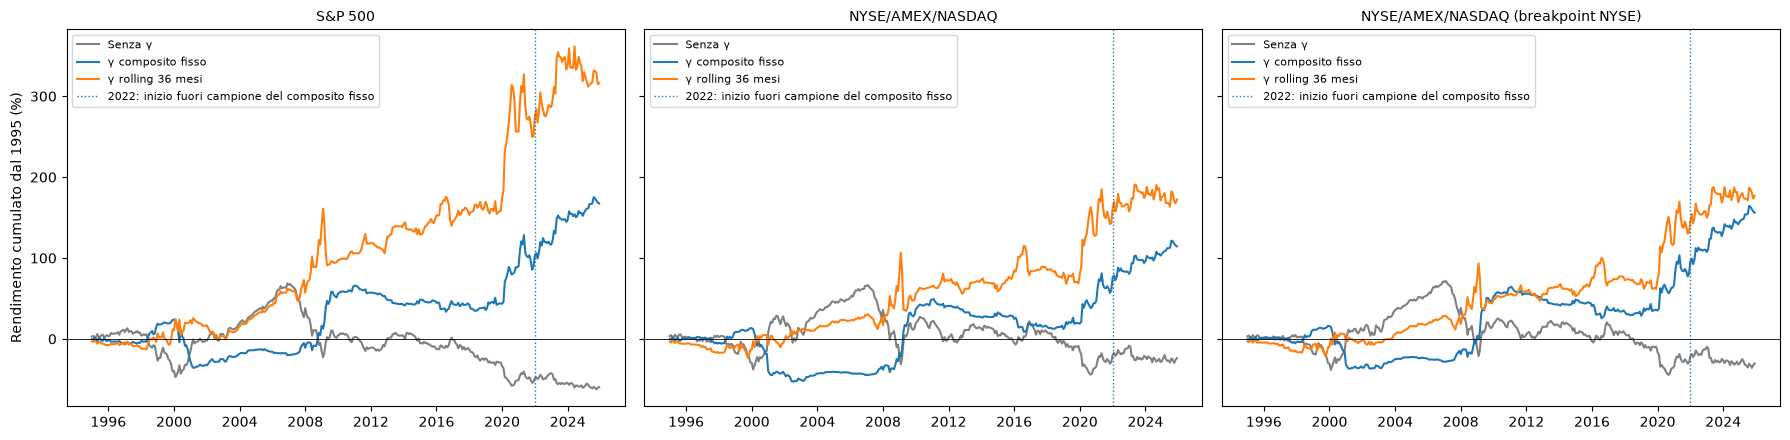

In [6]:
def leggi_ff(path):
    with zipfile.ZipFile(path) as z:
        righe = z.read(z.namelist()[0]).decode("latin-1").splitlines()
    header, dati = None, []
    for riga in righe:
        parti = [x.strip() for x in riga.split(",")]
        mensile = len(parti[0]) == 6 and parti[0].isdigit()
        if header is None and len(parti) > 1 and parti[0] == "":
            header = parti[1:]
        elif header and mensile:
            dati.append(parti)
        elif header and dati:
            break
    df = pd.DataFrame(dati).set_index(0).astype(float) / 100
    df.columns = header[:df.shape[1]]
    df.index = pd.PeriodIndex(df.index, freq="M")
    return df

ff = leggi_ff("Data/F-F_Research_Data_5_Factors_2x3_CSV.zip").join(leggi_ff("Data/F-F_Momentum_Factor_CSV.zip"))
fattori = [c for c in ff.columns if c != "RF"]

periodi = {"1990-2009": ("1990-01", "2009-12"), "2010-21": ("2010-01", "2021-12"),
           "2022-25": ("2022-01", "2099-12"), "Dal 1995": ("1995-01", "2099-12")}

righe, serie_tutte = [], {}
for nome, y in ls.items():
    versioni = {"Senza γ": y,
                "γ composito fisso": (gamma_fisso * y).dropna(),
                "γ rolling 36 mesi": (gamma_roll[nome] * y).dropna()}
    serie_tutte[nome] = versioni
    for vers, r in versioni.items():
        d = r.rename("r").to_frame().join(ff[fattori], how="inner")
        for per, (a, b) in periodi.items():
            x = d.loc[a:b]
            if len(x) < 24:
                continue
            m = hac(x["r"], x[fattori])
            righe.append({"Universo": nome, "Versione": vers, "Periodo": per, "Mesi": len(x),
                          "Rend. mensile": f"{x['r'].mean()*100:.2f}%", "Sharpe": round(sharpe(x["r"]), 2),
                          "Alfa": f"{m.params['const']*100:.2f}%", "t alfa": round(m.tvalues["const"], 2),
                          "Drawdown max": f"{drawdown_max(x['r'])*100:.1f}%"})
display(pd.DataFrame(righe).set_index(["Universo", "Versione", "Periodo"]))

# --- rendimento annuo per versione, dal 1995
for nome, versioni in serie_tutte.items():
    t = pd.concat({v: r.loc["1995-01":] for v, r in versioni.items()}, axis=1).dropna()
    print(f"\n{nome}: rendimento annuo (%)")
    display((t.groupby(t.index.year).apply(lambda g: (1 + g).prod() - 1) * 100).round(1))

# --- rendimento cumulato dal 1995
fig, axes = plt.subplots(1, len(serie_tutte), figsize=(6 * len(serie_tutte), 4.5), sharey=True)
for ax, (nome, versioni) in zip(axes, serie_tutte.items()):
    for (vers, r), col in zip(versioni.items(), ["grey", "tab:blue", "tab:orange"]):
        z = r.loc["1995-01":]
        ax.plot(z.index.to_timestamp(), ((1 + z).cumprod() - 1) * 100, color=col, label=vers)
    ax.axvline(pd.Timestamp("2022-01-01"), color="tab:blue", ls=":", lw=1,
               label="2022: inizio fuori campione del composito fisso")
    ax.axhline(0, color="black", lw=0.6)
    ax.set_title(nome, fontsize=10); ax.legend(fontsize=8)
axes[0].set_ylabel("Rendimento cumulato dal 1995 (%)")
plt.tight_layout(); plt.show()

## 9. Controllo sui guadagni nelle crisi (2008 e 2020)

1. **Mese per mese** nel 2008-09 e nel 2020: γ, rendimento value-growth, rendimento della strategia.
   γ deve cambiare segno *prima* dei grandi movimenti, non nello stesso mese.
2. **Test con un mese di ritardo in più:** se γ usasse per errore dati dello stesso mese, ritardandolo di un mese
   i risultati crollerebbero. Se restano simili, non c'è look-ahead.
3. **Peso delle crisi:** risultati escludendo 2008-09 e 2020, per vedere se la strategia dipende solo da quegli anni.

In [7]:
y = ls["S&P 500"]

# --- 1. mese per mese nelle crisi
dett = pd.DataFrame({"γ fisso": gamma_fisso, "γ rolling 36": gamma_roll["S&P 500"],
                     "Value-growth": y,
                     "Strategia γ fisso": gamma_fisso * y,
                     "Strategia γ rolling": gamma_roll["S&P 500"] * y}).dropna()
for a, b in [("2008-01", "2009-12"), ("2019-10", "2021-03")]:
    print(f"\nMese per mese {a} → {b} (rendimenti in %)")
    x = dett.loc[a:b].copy()
    for c in ["Value-growth", "Strategia γ fisso", "Strategia γ rolling"]:
        x[c] = (x[c] * 100).round(1)
    display(x.round(2))

# --- 2. test con un mese di ritardo in più
gf_lag = gamma_fisso.shift(1)
gr_lag = gamma_roll["S&P 500"].shift(1)
test = {"γ fisso (normale)": gamma_fisso * y, "γ fisso (ritardo +1 mese)": gf_lag * y,
        "γ rolling (normale)": gamma_roll["S&P 500"] * y, "γ rolling (ritardo +1 mese)": gr_lag * y}

# --- 3. esclusione degli anni di crisi
crisi = [2008, 2009, 2020]
righe = []
for nome, r in test.items():
    r = r.dropna().loc["1995-01":]
    senza = r[~r.index.year.isin(crisi)]
    righe.append({"Versione": nome,
                  "Rend. mensile": f"{r.mean()*100:.2f}%", "Sharpe": round(sharpe(r), 2),
                  "Rend. mensile senza 2008-09 e 2020": f"{senza.mean()*100:.2f}%",
                  "Sharpe senza 2008-09 e 2020": round(sharpe(senza), 2)})
print("\nS&P 500 dal 1995: ritardo extra ed esclusione delle crisi")
display(pd.DataFrame(righe).set_index("Versione"))


Mese per mese 2008-01 → 2009-12 (rendimenti in %)


,γ fisso,γ rolling 36,Value-growth,Strategia γ fisso,Strategia γ rolling
2008-01,-0.70,-1.00,9.0,-6.3,-9.0
2008-02,-0.99,-1.00,-6.2,6.1,6.2
2008-03,-0.40,-1.00,-2.6,1.1,2.6
2008-04,-0.49,-1.00,-0.7,0.3,0.7
2008-05,0.14,-0.81,-6.5,-0.9,5.3
2008-06,0.84,-1.00,-11.1,-9.3,11.1
2008-07,1.00,-1.00,6.6,6.6,-6.6
2008-08,0.47,-1.00,-0.4,-0.2,0.4
2008-09,-0.57,-1.00,0.4,-0.2,-0.4
2008-10,-1.00,-1.00,-7.6,7.6,7.6



Mese per mese 2019-10 → 2021-03 (rendimenti in %)


,γ fisso,γ rolling 36,Value-growth,Strategia γ fisso,Strategia γ rolling
2019-10,-0.95,-1.00,-0.5,0.5,0.5
2019-11,-1.00,-1.00,-0.7,0.7,0.7
2019-12,-0.18,-1.00,-0.0,0.0,0.0
2020-01,0.05,-1.00,-6.3,-0.3,6.3
2020-02,-0.45,-1.00,-3.6,1.6,3.6
2020-03,-1.00,-1.00,-16.9,16.9,16.9
2020-04,-1.00,-1.00,-2.6,2.6,2.6
2020-05,-1.00,-1.00,-3.5,3.5,3.5
2020-06,-1.00,-1.00,-4.4,4.4,4.4
2020-07,0.46,-1.00,-5.4,-2.5,5.4



S&P 500 dal 1995: ritardo extra ed esclusione delle crisi


,Rend. mensile,Sharpe,Rend. mensile senza 2008-09 e 2020,Sharpe senza 2008-09 e 2020
Versione,,,,
γ fisso (normale),0.31%,0.35,0.11%,0.14
γ fisso (ritardo +1 mese),0.25%,0.29,-0.00%,-0.01
γ rolling (normale),0.45%,0.44,0.34%,0.39
γ rolling (ritardo +1 mese),0.25%,0.25,0.14%,0.15


## 10. La rolling è timing sui tassi o momentum del fattore?

Nella regressione rolling la costante è il rendimento medio del value-growth negli ultimi 36 mesi.
Confronto tre versioni di γ (S&P 500, dal 1995):
- **γ rolling 36** (costante + segnali sui tassi), come prima;
- **γ momentum**: solo il rendimento medio degli ultimi 36 mesi, standardizzato e limitato tra −1 e +1 (nessun segnale sui tassi);
- **γ rolling senza costante**: solo i segnali sui tassi.

Se γ momentum va come la rolling, la rolling funziona per il momentum del fattore, non per i tassi.

In [8]:
y = ls["S&P 500"]

# gamma momentum: media degli ultimi 36 mesi / suo errore standard, limitata tra -1 e +1 (dati fino a t-1)
media = y.rolling(36).mean().shift(1)
err_std = (y.rolling(36).std() / np.sqrt(36)).shift(1)
gamma_mom = (media / err_std / 2).clip(-1, 1)

# gamma rolling senza costante: solo i segnali sui tassi
def gamma_rolling_senza_costante(y, W=36):
    X = pd.concat({k: segnali[k].shift(1) for k in ["Pendenza curva", "Variazione 2 anni (3m)"]}, axis=1)
    d = pd.concat([y.rename("y"), X], axis=1).dropna()
    out = {}
    for i in range(W, len(d)):
        train = d.iloc[i - W:i]
        b = sm.OLS(train["y"], train[X.columns]).fit().params
        sd = (train[X.columns] @ b).std()
        prev = (d.iloc[i][X.columns] * b).sum()
        out[d.index[i]] = np.clip(prev / sd, -1, 1) if sd > 0 else 0.0
    return pd.Series(out)

gamma_nocost = gamma_rolling_senza_costante(y)

versioni = {"γ rolling 36 (costante + tassi)": gamma_roll["S&P 500"],
            "γ momentum (solo passato del fattore)": gamma_mom,
            "γ rolling senza costante (solo tassi)": gamma_nocost,
            "γ composito fisso": gamma_fisso}
righe = []
for nome, g in versioni.items():
    r = (g * y).dropna().loc["1995-01":]
    d = r.rename("r").to_frame().join(ff[fattori], how="inner")
    m = hac(d["r"], d[fattori])
    righe.append({"Versione": nome, "Rend. mensile": f"{r.mean()*100:.2f}%", "Sharpe": round(sharpe(r), 2),
                  "Alfa": f"{m.params['const']*100:.2f}%", "t alfa": round(m.tvalues["const"], 2),
                  "Mesi con |γ| = 1": f"{(g.loc['1995-01':].abs() >= 0.999).mean()*100:.0f}%"})
display(pd.DataFrame(righe).set_index("Versione"))

print("\nCorrelazione tra le versioni di γ (dal 1995):")
display(pd.concat(versioni, axis=1).loc["1995-01":].dropna().corr().round(2))

,Rend. mensile,Sharpe,Alfa,t alfa,Mesi con |γ| = 1
Versione,,,,,
γ rolling 36 (costante + tassi),0.45%,0.44,0.60%,3.41,47%
γ momentum (solo passato del fattore),0.07%,0.09,0.07%,0.51,15%
γ rolling senza costante (solo tassi),0.47%,0.50,0.54%,2.72,41%
γ composito fisso,0.31%,0.35,0.37%,1.70,20%



Correlazione tra le versioni di γ (dal 1995):


,γ rolling 36 (costante + tassi),γ momentum (solo passato del fattore),γ rolling senza costante (solo tassi),γ composito fisso
γ rolling 36 (costante + tassi),1.00,0.42,0.70,0.05
γ momentum (solo passato del fattore),0.42,1.00,0.08,-0.05
γ rolling senza costante (solo tassi),0.70,0.08,1.00,0.19
γ composito fisso,0.05,-0.05,0.19,1.00


## 11. Alfa aggiustato per il rischio con diversi modelli

Regressione dei rendimenti mensili (long-short, quindi senza sottrarre il risk-free) su:

| Modello | Fattori |
|---|---|
| CAPM | Mercato |
| FF3 | Mercato, SMB, HML |
| FF3 + MOM | FF3 + momentum |
| FF5 | Mercato, SMB, HML, RMW, CMA |
| FF5 + MOM | FF5 + momentum |
| Q | Mercato, size (ME), investimento (IA), redditività (ROE) – Hou, Xue, Zhang |
| Q5 | Q + crescita attesa (EG) |

Errori standard Newey-West (6 ritardi). Periodi: dal 1995 e 2022-25.
Nota: per la strategia senza γ i modelli con HML catturano l'esposizione statica al value;
per le strategie con γ l'alfa misura il valore del timing.

In [9]:
import glob, urllib.request

# --- FF3 originale (scaricato dal sito di Kenneth French, se non c'è già)
if not glob.glob("Data/F-F_Research_Data_Factors_CSV.zip"):
    url = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/F-F_Research_Data_Factors_CSV.zip"
    with open("Data/F-F_Research_Data_Factors_CSV.zip", "wb") as f:
        f.write(urllib.request.urlopen(url).read())
ff3 = leggi_ff("Data/F-F_Research_Data_Factors_CSV.zip")

# --- fattori Q (file scaricato a mano da global-q.org)
fq = glob.glob("Data/q5_factors_monthly*.csv")[0]
q = pd.read_csv(fq)
q.columns = q.columns.str.upper()
q.index = pd.to_datetime(dict(year=q["YEAR"], month=q["MONTH"], day=1)).dt.to_period("M")
q = q[["R_MKT", "R_ME", "R_IA", "R_ROE", "R_EG"]] / 100
print("Fattori Q fino a:", q.index.max(), "| FF fino a:", ff.index.max())

# --- i sette modelli
modelli = {
    "CAPM":      ff[["Mkt-RF"]],
    "FF3":       ff3[["Mkt-RF", "SMB", "HML"]],
    "FF3 + MOM": ff3[["Mkt-RF", "SMB", "HML"]].join(ff[["Mom"]]),
    "FF5":       ff[["Mkt-RF", "SMB", "HML", "RMW", "CMA"]],
    "FF5 + MOM": ff[["Mkt-RF", "SMB", "HML", "RMW", "CMA", "Mom"]],
    "Q":         q[["R_MKT", "R_ME", "R_IA", "R_ROE"]],
    "Q5":        q[["R_MKT", "R_ME", "R_IA", "R_ROE", "R_EG"]],
}

periodi_alfa = {"Dal 1995": ("1995-01", "2099-12"), "2022-25": ("2022-01", "2099-12")}

righe = []
for universo, versioni in serie_tutte.items():
    for vers, r in versioni.items():
        for nome_m, F in modelli.items():
            d = r.rename("r").to_frame().join(F, how="inner")
            for per, (a, b) in periodi_alfa.items():
                x = d.loc[a:b]
                if len(x) < 24:
                    continue
                m = hac(x["r"], x[F.columns])
                righe.append({"Universo": universo, "Versione": vers, "Periodo": per, "Modello": nome_m,
                              "alfa (t)": f"{m.params['const']*100:.2f}% ({m.tvalues['const']:.2f})",
                              "R²": round(m.rsquared, 2), "Mesi": len(x)})

tab = pd.DataFrame(righe)
ordine = list(modelli)
for per in periodi_alfa:
    print(f"\nAlfa mensile (t-stat), periodo {per}")
    display(tab[tab["Periodo"] == per]
            .pivot_table(index=["Universo", "Versione"], columns="Modello", values="alfa (t)", aggfunc="first")
            [ordine])
    print(f"R² delle regressioni, periodo {per}")
    display(tab[tab["Periodo"] == per]
            .pivot_table(index=["Universo", "Versione"], columns="Modello", values="R²", aggfunc="first")
            [ordine])

Fattori Q fino a: 2025-12 | FF fino a: 2026-09

Alfa mensile (t-stat), periodo Dal 1995


Modello                                                         CAPM  \
Universo                           Versione                            
NYSE/AMEX/NASDAQ                   Senza γ            -0.15% (-0.54)   
                                   γ composito fisso    0.22% (0.90)   
                                   γ rolling 36 mesi    0.52% (2.84)   
NYSE/AMEX/NASDAQ (breakpoint NYSE) Senza γ            -0.15% (-0.58)   
                                   γ composito fisso    0.26% (1.24)   
                                   γ rolling 36 mesi    0.48% (2.73)   
S&P 500                            Senza γ            -0.21% (-0.77)   
                                   γ composito fisso    0.27% (1.24)   
                                   γ rolling 36 mesi    0.56% (3.10)   

Modello                                                          FF3  \
Universo                           Versione                            
NYSE/AMEX/NASDAQ                   Senza γ            -0.33% (-2.21)   
                                   γ composito fisso    0.23% (0.98)   
                                   γ rolling 36 mesi    0.55% (2.91)   
NYSE/AMEX/NASDAQ (breakpoint NYSE) Senza γ            -0.31% (-2.82)   
                                   γ composito fisso    0.28% (1.43)   
                                   γ rolling 36 mesi    0.51% (2.89)   
S&P 500                            Senza γ            -0.40% (-3.13)   
                                   γ composito fisso    0.31% (1.60)   
                                   γ rolling 36 mesi    0.60% (3.39)   

Modello                                                    FF3 + MOM  \
Universo                           Versione                            
NYSE/AMEX/NASDAQ                   Senza γ              0.01% (0.10)   
                                   γ composito fisso    0.26% (0.81)   
                                   γ rolling 36 mesi    0.41% (2.04)   
NYSE/AMEX/NASDAQ (breakpoint NYSE) Senza γ            -0.03% (-0.31)   
                                   γ composito fisso    0.30% (1.13)   
                                   γ rolling 36 mesi    0.40% (2.12)   
S&P 500                            Senza γ            -0.18% (-1.54)   
                                   γ composito fisso    0.34% (1.47)   
                                   γ rolling 36 mesi    0.54% (2.93)   

Modello                                                          FF5  \
Universo                           Versione                            
NYSE/AMEX/NASDAQ                   Senza γ            -0.11% (-0.70)   
                                   γ composito fisso    0.29% (1.26)   
                                   γ rolling 36 mesi    0.51% (2.84)   
NYSE/AMEX/NASDAQ (breakpoint NYSE) Senza γ            -0.17% (-1.29)   
                                   γ composito fisso    0.32% (1.61)   
                                   γ rolling 36 mesi    0.52% (3.10)   
S&P 500                            Senza γ            -0.30% (-2.08)   
                                   γ composito fisso    0.34% (1.86)   
                                   γ rolling 36 mesi    0.66% (3.85)   

Modello                                                    FF5 + MOM  \
Universo                           Versione                            
NYSE/AMEX/NASDAQ                   Senza γ              0.16% (1.25)   
                                   γ composito fisso    0.32% (1.04)   
                                   γ rolling 36 mesi    0.40% (2.11)   
NYSE/AMEX/NASDAQ (breakpoint NYSE) Senza γ              0.07% (0.71)   
                                   γ composito fisso    0.33% (1.33)   
                                   γ rolling 36 mesi    0.43% (2.44)   
S&P 500                            Senza γ            -0.11% (-0.97)   
                                   γ composito fisso    0.37% (1.70)   
                                   γ rolling 36 mesi    0.60% (3.41)   

Modello                            

R² delle regressioni, periodo Dal 1995


Modello                                               CAPM   FF3  FF3 + MOM  \
Universo                           Versione                                   
NYSE/AMEX/NASDAQ                   Senza γ            0.05  0.60       0.82   
                                   γ composito fisso  0.01  0.01       0.02   
                                   γ rolling 36 mesi  0.07  0.08       0.14   
NYSE/AMEX/NASDAQ (breakpoint NYSE) Senza γ            0.04  0.67       0.86   
                                   γ composito fisso  0.00  0.02       0.02   
                                   γ rolling 36 mesi  0.06  0.08       0.13   
S&P 500                            Senza γ            0.01  0.65       0.77   
                                   γ composito fisso  0.01  0.04       0.05   
                                   γ rolling 36 mesi  0.03  0.07       0.09   

Modello                                                FF5  FF5 + MOM     Q  \
Universo                           Versione                                   
NYSE/AMEX/NASDAQ                   Senza γ            0.64       0.85  0.35   
                                   γ composito fisso  0.04       0.04  0.05   
                                   γ rolling 36 mesi  0.10       0.15  0.08   
NYSE/AMEX/NASDAQ (breakpoint NYSE) Senza γ            0.69       0.88  0.37   
                                   γ composito fisso  0.04       0.04  0.04   
                                   γ rolling 36 mesi  0.11       0.15  0.07   
S&P 500                            Senza γ            0.67       0.79  0.36   
                                   γ composito fisso  0.05       0.05  0.03   
                                   γ rolling 36 mesi  0.09       0.10  0.05   

Modello                                                 Q5  
Universo                           Versione                 
NYSE/AMEX/NASDAQ                   Senza γ            0.38  
                                   γ composito fisso  0.06  
                                   γ rolling 36 mesi  0.08  
NYSE/AMEX/NASDAQ (breakpoint NYSE) Senza γ            0.40  
                                   γ composito fisso  0.05  
                                   γ rolling 36 mesi  0.08  
S&P 500                            Senza γ            0.39  
                                   γ composito fisso  0.04  
                                   γ rolling 36 mesi  0.05


Alfa mensile (t-stat), periodo 2022-25


Modello                                                         CAPM  \
Universo                           Versione                            
NYSE/AMEX/NASDAQ                   Senza γ              0.29% (0.57)   
                                   γ composito fisso    0.68% (2.16)   
                                   γ rolling 36 mesi    0.30% (0.93)   
NYSE/AMEX/NASDAQ (breakpoint NYSE) Senza γ              0.13% (0.26)   
                                   γ composito fisso    0.79% (2.56)   
                                   γ rolling 36 mesi    0.45% (1.43)   
S&P 500                            Senza γ            -0.06% (-0.12)   
                                   γ composito fisso    0.75% (2.30)   
                                   γ rolling 36 mesi    0.41% (1.03)   

Modello                                                          FF3  \
Universo                           Versione                            
NYSE/AMEX/NASDAQ                   Senza γ              0.05% (0.25)   
                                   γ composito fisso    0.45% (1.78)   
                                   γ rolling 36 mesi    0.05% (0.17)   
NYSE/AMEX/NASDAQ (breakpoint NYSE) Senza γ            -0.09% (-0.56)   
                                   γ composito fisso    0.58% (2.23)   
                                   γ rolling 36 mesi    0.20% (0.58)   
S&P 500                            Senza γ            -0.43% (-1.89)   
                                   γ composito fisso    0.63% (2.03)   
                                   γ rolling 36 mesi    0.23% (0.50)   

Modello                                                    FF3 + MOM  \
Universo                           Versione                            
NYSE/AMEX/NASDAQ                   Senza γ              0.09% (0.59)   
                                   γ composito fisso    0.46% (1.85)   
                                   γ rolling 36 mesi    0.06% (0.18)   
NYSE/AMEX/NASDAQ (breakpoint NYSE) Senza γ            -0.06% (-0.43)   
                                   γ composito fisso    0.59% (2.24)   
                                   γ rolling 36 mesi    0.19% (0.56)   
S&P 500                            Senza γ            -0.42% (-1.90)   
                                   γ composito fisso    0.64% (2.14)   
                                   γ rolling 36 mesi    0.23% (0.50)   

Modello                                                          FF5  \
Universo                           Versione                            
NYSE/AMEX/NASDAQ                   Senza γ            -0.01% (-0.03)   
                                   γ composito fisso    0.41% (1.70)   
                                   γ rolling 36 mesi    0.06% (0.20)   
NYSE/AMEX/NASDAQ (breakpoint NYSE) Senza γ            -0.16% (-0.98)   
                                   γ composito fisso    0.56% (2.29)   
                                   γ rolling 36 mesi    0.18% (0.57)   
S&P 500                            Senza γ            -0.38% (-1.51)   
                                   γ composito fisso    0.53% (1.88)   
                                   γ rolling 36 mesi    0.18% (0.45)   

Modello                                                    FF5 + MOM  \
Universo                           Versione                            
NYSE/AMEX/NASDAQ                   Senza γ              0.06% (0.39)   
                                   γ composito fisso    0.44% (1.85)   
                                   γ rolling 36 mesi    0.07% (0.23)   
NYSE/AMEX/NASDAQ (breakpoint NYSE) Senza γ            -0.10% (-0.70)   
                                   γ composito fisso    0.57% (2.34)   
                                   γ rolling 36 mesi    0.17% (0.53)   
S&P 500                            Senza γ            -0.35% (-1.43)   
                                   γ composito fisso    0.55% (2.03)   
                                   γ rolling 36 mesi    0.19% (0.46)   

Modello                            

R² delle regressioni, periodo 2022-25


Modello                                               CAPM   FF3  FF3 + MOM  \
Universo                           Versione                                   
NYSE/AMEX/NASDAQ                   Senza γ            0.01  0.86       0.90   
                                   γ composito fisso  0.01  0.13       0.14   
                                   γ rolling 36 mesi  0.00  0.10       0.10   
NYSE/AMEX/NASDAQ (breakpoint NYSE) Senza γ            0.01  0.88       0.92   
                                   γ composito fisso  0.01  0.11       0.11   
                                   γ rolling 36 mesi  0.01  0.11       0.11   
S&P 500                            Senza γ            0.05  0.84       0.85   
                                   γ composito fisso  0.00  0.04       0.05   
                                   γ rolling 36 mesi  0.00  0.06       0.06   

Modello                                                FF5  FF5 + MOM     Q  \
Universo                           Versione                                   
NYSE/AMEX/NASDAQ                   Senza γ            0.87       0.90  0.62   
                                   γ composito fisso  0.15       0.17  0.16   
                                   γ rolling 36 mesi  0.10       0.11  0.13   
NYSE/AMEX/NASDAQ (breakpoint NYSE) Senza γ            0.90       0.92  0.61   
                                   γ composito fisso  0.13       0.13  0.14   
                                   γ rolling 36 mesi  0.12       0.12  0.12   
S&P 500                            Senza γ            0.85       0.85  0.62   
                                   γ composito fisso  0.08       0.09  0.06   
                                   γ rolling 36 mesi  0.08       0.08  0.08   

Modello                                                 Q5  
Universo                           Versione                 
NYSE/AMEX/NASDAQ                   Senza γ            0.66  
                                   γ composito fisso  0.16  
                                   γ rolling 36 mesi  0.15  
NYSE/AMEX/NASDAQ (breakpoint NYSE) Senza γ            0.66  
                                   γ composito fisso  0.14  
                                   γ rolling 36 mesi  0.13  
S&P 500                            Senza γ            0.69  
                                   γ composito fisso  0.06  
                                   γ rolling 36 mesi  0.08

## 12. Alfa per blocchi di 5 anni

Alfa mensile (t-stat Newey-West) per blocchi di 5 anni, con i sette modelli (CAPM, FF3, FF3+MOM, FF5, FF5+MOM, Q, Q5),
per ciascuna versione della strategia. Ogni blocco ha circa 60 mesi: le stime sono rumorose,
conta soprattutto la continuità del segno.
Il grafico mostra l'alfa FF5 + MOM per blocco con intervallo di confidenza al 95%.


S&P 500 – Senza γ: alfa mensile (t) per blocco


Modello,CAPM,FF3,FF3 + MOM,FF5,FF5 + MOM,Q,Q5
Blocco,,,,,,,
1990-1994,0.33% (0.81),0.06% (0.3),0.43% (1.72),0.53% (2.41),0.79% (4.07),0.93% (2.62),0.69% (1.54)
1995-1999,-0.5% (-0.86),-0.88% (-2.66),-0.03% (-0.12),-1.12% (-3.33),-0.24% (-1.01),-1.19% (-1.99),-1.14% (-1.94)
2000-2004,1.43% (2.63),0.46% (1.73),0.3% (1.84),0.64% (1.5),0.41% (1.54),1.23% (1.86),1.49% (1.96)
2005-2009,-0.33% (-0.73),-0.38% (-0.93),-0.46% (-1.53),-0.18% (-0.6),-0.29% (-1.11),-0.07% (-0.19),0.2% (0.53)
2010-2014,-0.25% (-0.63),-0.0% (-0.01),0.14% (0.59),0.1% (0.61),0.13% (0.8),-0.18% (-0.49),-0.03% (-0.09)
2015-2019,-0.66% (-2.43),-0.33% (-2.19),-0.29% (-2.3),-0.3% (-1.98),-0.25% (-2.0),-0.35% (-1.19),-0.11% (-0.51)
2020-2025,-0.64% (-0.83),-0.61% (-2.19),-0.53% (-1.99),-0.54% (-2.26),-0.46% (-1.94),-0.27% (-0.56),-0.28% (-0.75)



S&P 500 – γ composito fisso: alfa mensile (t) per blocco


Modello,CAPM,FF3,FF3 + MOM,FF5,FF5 + MOM,Q,Q5
Blocco,,,,,,,
1990-1994,0.46% (2.61),0.36% (3.28),0.37% (3.26),0.4% (2.93),0.41% (2.92),0.5% (3.13),0.44% (2.56)
1995-1999,0.3% (1.03),0.4% (2.02),0.2% (1.07),0.5% (2.31),0.3% (1.38),0.43% (1.86),0.44% (1.49)
2000-2004,-0.43% (-0.7),-0.23% (-0.54),-0.14% (-0.41),-0.55% (-0.97),-0.43% (-0.89),-0.56% (-0.85),-0.83% (-1.04)
2005-2009,1.01% (1.54),1.02% (1.56),0.92% (2.38),1.21% (1.88),1.08% (2.2),1.32% (2.34),0.97% (2.1)
2010-2014,-0.05% (-0.36),-0.07% (-0.4),-0.06% (-0.31),-0.16% (-0.95),-0.15% (-0.9),-0.13% (-0.87),-0.15% (-0.9)
2015-2019,0.05% (0.23),-0.05% (-0.18),-0.08% (-0.32),-0.1% (-0.37),-0.15% (-0.6),-0.13% (-0.5),-0.16% (-0.69)
2020-2025,1.05% (2.24),1.03% (2.08),1.11% (2.21),1.04% (2.09),1.14% (2.24),1.06% (2.35),1.06% (2.49)



S&P 500 – γ rolling 36 mesi: alfa mensile (t) per blocco


Modello,CAPM,FF3,FF3 + MOM,FF5,FF5 + MOM,Q,Q5
Blocco,,,,,,,
1990-1994,-0.04% (-0.14),-0.15% (-0.59),0.02% (0.09),0.27% (1.43),0.35% (1.79),0.07% (0.22),0.02% (0.04)
1995-1999,0.24% (0.73),0.46% (1.18),0.36% (0.86),0.63% (1.7),0.64% (1.59),1.12% (2.46),1.33% (2.97)
2000-2004,0.33% (0.98),-0.08% (-0.24),-0.15% (-0.5),0.49% (1.19),0.4% (1.14),0.34% (0.86),0.47% (1.06)
2005-2009,0.77% (2.6),0.8% (2.02),0.9% (2.57),0.73% (1.93),0.86% (2.18),0.6% (1.72),0.53% (1.11)
2010-2014,0.46% (1.97),0.52% (2.0),0.54% (2.05),0.58% (2.26),0.58% (2.27),0.66% (2.59),0.65% (2.5)
2015-2019,0.26% (1.09),0.12% (0.48),0.15% (0.56),0.17% (0.65),0.21% (0.77),0.27% (0.9),0.3% (1.05)
2020-2025,0.92% (1.46),0.8% (1.3),0.78% (1.26),0.78% (1.3),0.77% (1.26),0.72% (1.24),0.72% (1.23)


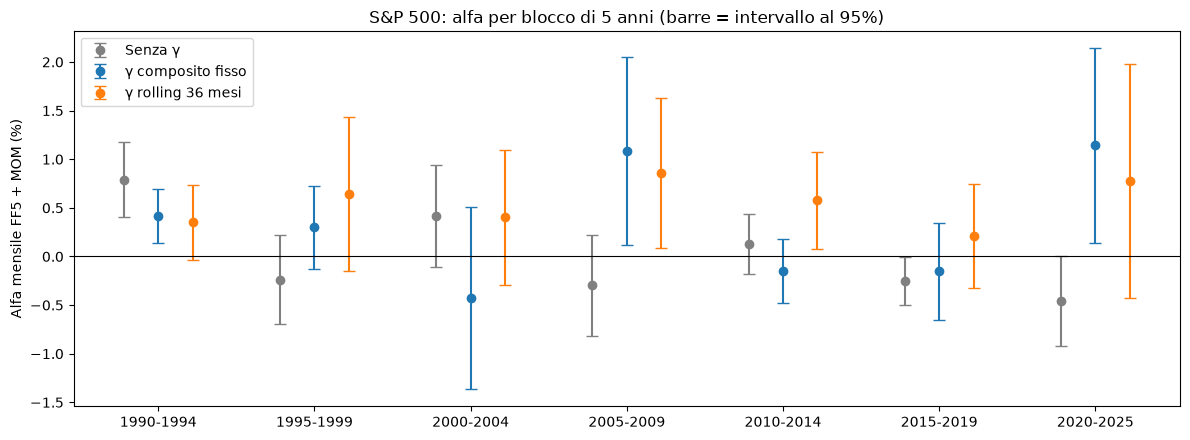

In [10]:
UNIVERSO = "S&P 500"     # oppure "NYSE/AMEX/NASDAQ" o "NYSE/AMEX/NASDAQ (breakpoint NYSE)"

blocchi = [("1990-01", "1994-12"), ("1995-01", "1999-12"), ("2000-01", "2004-12"),
           ("2005-01", "2009-12"), ("2010-01", "2014-12"), ("2015-01", "2019-12"), ("2020-01", "2025-12")]
etichetta = lambda a, b: f"{a[:4]}-{b[:4]}"

ris = []
for vers, r in serie_tutte[UNIVERSO].items():
    for nome_m, F in modelli.items():
        d = r.rename("r").to_frame().join(F, how="inner")
        for a, b in blocchi:
            x = d.loc[a:b]
            if len(x) < 36:
                continue
            m = hac(x["r"], x[F.columns])
            ris.append({"Versione": vers, "Modello": nome_m, "Blocco": etichetta(a, b), "Mesi": len(x),
                        "alfa": m.params["const"], "t": m.tvalues["const"], "se": m.bse["const"]})
ris = pd.DataFrame(ris)

for vers in serie_tutte[UNIVERSO]:
    x = ris[ris["Versione"] == vers].copy()
    x["alfa (t)"] = (x["alfa"] * 100).round(2).astype(str) + "% (" + x["t"].round(2).astype(str) + ")"
    print(f"\n{UNIVERSO} – {vers}: alfa mensile (t) per blocco")
    display(x.pivot(index="Blocco", columns="Modello", values="alfa (t)")[list(modelli)])

# --- grafico: alfa FF5 + MOM per blocco, con intervallo al 95%
g = ris[ris["Modello"] == "FF5 + MOM"]
versioni_g = list(serie_tutte[UNIVERSO])
etichette = [etichetta(a, b) for a, b in blocchi]
xpos = np.arange(len(etichette))
fig, ax = plt.subplots(figsize=(12, 4.5))
for k, (vers, col) in enumerate(zip(versioni_g, ["grey", "tab:blue", "tab:orange"])):
    z = g[g["Versione"] == vers].set_index("Blocco").reindex(etichette)
    ax.errorbar(xpos + (k - 1) * 0.22, z["alfa"] * 100, yerr=1.96 * z["se"] * 100,
                fmt="o", color=col, capsize=4, label=vers)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(xpos); ax.set_xticklabels(etichette)
ax.set_ylabel("Alfa mensile FF5 + MOM (%)")
ax.set_title(f"{UNIVERSO}: alfa per blocco di 5 anni (barre = intervallo al 95%)")
ax.legend(); plt.tight_layout(); plt.show()

## Turnover e costi di transazione (modello di Goyal)

**Turnover** del mese t+1: Turn = Σᵢ |Δwᵢ|, con Δwᵢ = γ_{t+1}·wᵢ,target − γ_t·wᵢ,drift.
- Il peso pre-ribilanciamento tiene conto del drift: wᵢ,drift = wᵢ,t·(1+rᵢ)/(1+r_gamba), separato per gamba long e short.
- Il turnover massimo per un long-short è 400%.

**Impatto di prezzo** in % del portafoglio: Σᵢ λᵢ·√(V₀·|Δwᵢ| / ADVᵢ)·|Δwᵢ|
- ADVᵢ = MthVol·|MthPrc| / 21, il volume giornaliero medio in dollari del mese in cui si scambia.
- λ = 2.5 / 1.5 / 1.0 (in %) per micro / small / large, con breakpoint NYSE al 20° e 50° percentile. Un ordine pari all'1% dell'ADV costa quindi 25 / 15 / 10 bps.
- Se l'ADV manca, lo sostituisco con la media della stessa classe di taglia nello stesso mese, come nella slide.

Poiché costo = √V₀ · K_t con K_t = Σᵢ λᵢ|Δwᵢ|^1.5/√ADVᵢ, l'alpha netta è α_lorda − √V₀·α_K. Il V₀ di pareggio, cioè quello che azzera l'alpha netta, è (α_lorda/α_K)².

In [11]:
import numpy as np, pandas as pd, statsmodels.api as sm

# ---------- parametri ----------
V0_GRID = [1e7, 1e8, 1e9, 1e10]                              # 10M, 100M, 1B, 10B $
LAMBDA  = {"micro": 0.025, "small": 0.015, "large": 0.010}   # 1% ADV -> 25/15/10 bps
GIORNI  = 21
INIZIO  = pd.Period("1995-01", "M")
LAG_HAC = 6
UNIVERSI = {"S&P 500": ("sp500", False),
            "NYSE/AMEX/NASDAQ": ("tutte", False),
            "NYSE/AMEX/NASDAQ (breakpoint NYSE)": ("tutte", True)}

def a_periodi(x):
    x = x.copy()
    if not isinstance(x.index, pd.PeriodIndex):
        x.index = pd.to_datetime(x.index).to_period("M")
    return x.astype(float)

# ---------- 1. ADV in dollari ----------
vol = pd.read_csv("Data/jhvzegjsguw3gw3k_csv.zip",
                  usecols=["PERMNO", "MthCalDt", "MthPrc", "MthVol"])
vol["mese"] = pd.to_datetime(vol["MthCalDt"]).dt.to_period("M")
vol["ADV"] = vol["MthVol"] * vol["MthPrc"].abs() / GIORNI
vol.loc[~(vol["ADV"] > 0), "ADV"] = np.nan
vol = vol.drop_duplicates(["PERMNO", "mese"])[["PERMNO", "mese", "ADV"]]

# ---------- 2. classi di taglia (breakpoint NYSE) ----------
bp = (crsp[crsp["primaryexch"] == "N"].groupby("mese")["MthCap"]
      .quantile([0.2, 0.5]).unstack())
bp.columns = ["p20", "p50"]
info = crsp[["PERMNO", "mese", "MthCap", "sp500"]].join(bp, on="mese")
info["taglia"] = np.select([info["MthCap"] < info["p20"], info["MthCap"] < info["p50"]],
                           ["micro", "small"], "large")
info.loc[info["MthCap"].isna(), "taglia"] = "micro"
info = info.merge(vol, on=["PERMNO", "mese"], how="left")
media_taglia = info.groupby(["mese", "taglia"])["ADV"].mean()

ult = info[info["sp500"].astype(bool) & (info["mese"] > info["mese"].max() - 12)]
print(f"Controllo: ADV mediana S&P 500 ultimo anno = ${ult['ADV'].median()/1e6:,.0f}M "
      "(deve essere nell'ordine delle centinaia di milioni)")
info = info[["PERMNO", "mese", "taglia", "ADV"]]

# ---------- 3. pesi target e pesi dopo il drift ----------
def pesi(df, breakpoint_nyse):
    df = df.dropna(subset=["BM", "MthCap", "ret_next"]).copy()
    base = df[df["primaryexch"] == "N"] if breakpoint_nyse else df
    q = base.groupby("mese")["BM"].quantile([1/3, 2/3]).unstack()
    q.columns = ["q1", "q2"]
    df = df.join(q, on="mese")
    df["lato"] = np.select([df["BM"] >= df["q2"], df["BM"] <= df["q1"]], [1, -1], 0)
    df = df[df["lato"] != 0].copy()
    df["w"] = df["lato"] * df["MthCap"] / df.groupby(["mese", "lato"])["MthCap"].transform("sum")
    return df[["PERMNO", "mese", "lato", "w", "ret_next"]]

def componenti(t):
    t = t.copy()
    t["wr"] = t["w"].abs() * t["ret_next"]
    r_lato = t.groupby(["mese", "lato"])["wr"].transform("sum")
    t["w_drift"] = t["w"] * (1 + t["ret_next"]) / (1 + r_lato)
    tgt = t[["PERMNO", "mese", "w"]]
    pre = t[["PERMNO", "mese", "w_drift"]].assign(mese=t["mese"] + 1)
    c = tgt.merge(pre, on=["PERMNO", "mese"], how="outer").fillna({"w": 0.0, "w_drift": 0.0})
    c = c[c["mese"] <= t["mese"].max()]
    c = c.merge(info, on=["PERMNO", "mese"], how="left")
    c["taglia"] = c["taglia"].fillna("micro")
    mt = media_taglia.reindex(pd.MultiIndex.from_frame(c[["mese", "taglia"]])).values
    c["ADV"] = c["ADV"].fillna(pd.Series(mt, index=c.index))
    c["ADV"] = c["ADV"].fillna(c.groupby("taglia")["ADV"].transform("mean"))
    c["lam"] = c["taglia"].map(LAMBDA)
    ls = (t["w"] * t["ret_next"]).groupby(t["mese"]).sum()
    return c, ls

# ---------- 4. fattori FF5 + MOM ----------
F = a_periodi(ff)
fatt = F.drop(columns=[c for c in F.columns if c.upper() == "RF"])
if fatt.abs().mean().mean() > 0.2:
    fatt = fatt / 100

def alpha(y):
    d = pd.concat([y.rename("y"), fatt], axis=1, join="inner").dropna()
    r = sm.OLS(d["y"], sm.add_constant(d.drop(columns="y"))).fit(
        cov_type="HAC", cov_kwds={"maxlags": LAG_HAC})
    return r.params["const"], r.tvalues["const"]

# ---------- 5. calcolo ----------
righe_costi, righe_alpha = [], []
for u, (flag, bp_nyse) in UNIVERSI.items():
    c, ls_mio = componenti(pesi(crsp[crsp[flag].astype(bool)], bp_nyse))

    base = a_periodi(serie_tutte[u]["Senza γ"])
    scala = 100 if base.abs().mean() > 0.2 else 1
    ls_sh = ls_mio.copy(); ls_sh.index = ls_sh.index + 1
    c0 = pd.concat([ls_mio, base], axis=1, join="inner").corr().iloc[0, 1]
    c1 = pd.concat([ls_sh, base], axis=1, join="inner").corr().iloc[0, 1]
    off = 1 if c1 > c0 else 0
    print(f"{u}: correlazione pesi ricostruiti vs serie del notebook = {max(c0, c1):.3f}")

    for v in serie_tutte[u]:
        y = a_periodi(serie_tutte[u][v]) / scala
        g = (y / (base / scala)).replace([np.inf, -np.inf], np.nan).ffill()
        g.index = g.index - off                                   # γ per mese di formazione
        if v == "Senza γ":
            g = pd.Series(1.0, index=ls_mio.index)
        gm = c["mese"].map(g).fillna(0).values
        gp = (c["mese"] - 1).map(g).fillna(0).values
        dw = np.abs(gm * c["w"].values - gp * c["w_drift"].values)
        tmp = pd.DataFrame({"mese": c["mese"], "dw": dw,
                            "k": c["lam"].values * dw**1.5 / np.sqrt(c["ADV"].values)})
        agg = tmp.groupby("mese")[["dw", "k"]].sum()
        agg.index = agg.index + off                               # allineo al mese del rendimento

        y = y[y.index >= INIZIO].dropna()
        K = agg["k"].reindex(y.index).fillna(0)
        turn = agg["dw"].reindex(y.index).fillna(0)

        a_l, t_l = alpha(y)
        a_k, _ = alpha(K)
        pareggio = (a_l / a_k) ** 2 / 1e6 if (a_l > 0 and a_k > 0) else 0

        rc = {"Universo": u, "Versione": v, "Turnover medio %/mese": f"{turn.mean()*100:.0f}"}
        ra = {"Universo": u, "Versione": v, "α lorda": f"{a_l*100:.2f} ({t_l:.2f})"}
        for V0 in V0_GRID:
            nome = f"{V0/1e6:,.0f}M" if V0 < 1e9 else f"{V0/1e9:,.0f}B"
            netto = y - np.sqrt(V0) * K
            a_n, t_n = alpha(netto)
            rc[f"Costo %/mese {nome}"] = f"{(np.sqrt(V0) * K).mean()*100:.2f}"
            ra[f"α netta {nome}"] = f"{a_n*100:.2f} ({t_n:.2f})"
            ra[f"Sharpe netto {nome}"] = f"{netto.mean()/netto.std()*np.sqrt(12):.2f}"
        ra["V0 di pareggio ($M)"] = f"{pareggio:,.0f}"
        righe_costi.append(rc); righe_alpha.append(ra)

pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print(f"\nTurnover e costi medi (dal {INIZIO})")
display(pd.DataFrame(righe_costi).set_index(["Universo", "Versione"]))
print(f"\nAlpha FF5+MOM % mensile (t HAC), lorda e netta, dal {INIZIO}")
display(pd.DataFrame(righe_alpha).set_index(["Universo", "Versione"]))

Controllo: ADV mediana S&P 500 ultimo anno = $278M (deve essere nell'ordine delle centinaia di milioni)
S&P 500: correlazione pesi ricostruiti vs serie del notebook = 1.000
NYSE/AMEX/NASDAQ: correlazione pesi ricostruiti vs serie del notebook = 1.000
NYSE/AMEX/NASDAQ (breakpoint NYSE): correlazione pesi ricostruiti vs serie del notebook = 1.000

Turnover e costi medi (dal 1995-01)


Turnover medio %/mese Costo %/mese 10M Costo %/mese 100M Costo %/mese 1B Costo %/mese 10B
Universo                           Versione                                                                                                   
S&P 500                            Senza γ                              24             0.01              0.02            0.06             0.19
                                   γ composito fisso                    59             0.01              0.03            0.10             0.33
                                   γ rolling 36 mesi                    79             0.02              0.06            0.19             0.59
NYSE/AMEX/NASDAQ                   Senza γ                              32             0.01              0.05            0.14             0.46
                                   γ composito fisso                    63             0.02              0.06            0.18             0.56
                                   γ rolling 36 mesi                    86             0.03              0.10            0.32             1.01
NYSE/AMEX/NASDAQ (breakpoint NYSE) Senza γ                              28             0.01              0.03            0.10             0.33
                                   γ composito fisso                    61             0.01              0.04            0.14             0.44
                                   γ rolling 36 mesi                    83             0.03              0.08            0.26             0.82


Alpha FF5+MOM % mensile (t HAC), lorda e netta, dal 1995-01


α lorda    α netta 10M Sharpe netto 10M   α netta 100M Sharpe netto 100M     α netta 1B Sharpe netto 1B    α netta 10B Sharpe netto 10B V0 di pareggio ($M)
Universo                           Versione                                                                                                                                                                            
S&P 500                            Senza γ            -0.11 (-0.97)  -0.11 (-1.03)            -0.13  -0.12 (-1.15)             -0.14  -0.17 (-1.53)           -0.17  -0.30 (-2.70)            -0.28                   0
                                   γ composito fisso    0.37 (1.70)    0.36 (1.66)             0.34    0.34 (1.55)              0.31    0.27 (1.23)            0.23    0.04 (0.19)            -0.02              12,597
                                   γ rolling 36 mesi    0.60 (3.41)    0.58 (3.30)             0.42    0.54 (3.06)              0.38    0.41 (2.30)            0.25    0.00 (0.02)            -0.14              10,108
NYSE/AMEX/NASDAQ                   Senza γ              0.16 (1.25)    0.15 (1.15)             0.01    0.12 (0.92)             -0.01    0.02 (0.18)           -0.08  -0.28 (-2.27)            -0.32               1,346
                                   γ composito fisso    0.32 (1.04)    0.30 (0.98)             0.24    0.26 (0.86)              0.21    0.14 (0.47)            0.09  -0.23 (-0.74)            -0.28               3,324
                                   γ rolling 36 mesi    0.40 (2.11)    0.36 (1.94)             0.28    0.30 (1.56)              0.22    0.08 (0.42)            0.02  -0.59 (-2.42)            -0.57               1,602
NYSE/AMEX/NASDAQ (breakpoint NYSE) Senza γ              0.07 (0.71)    0.06 (0.61)            -0.02    0.04 (0.38)             -0.04  -0.03 (-0.35)           -0.09  -0.25 (-2.67)            -0.28                 456
                                   γ composito fisso    0.33 (1.33)    0.32 (1.27)             0.32    0.29 (1.15)              0.29    0.19 (0.77)            0.18  -0.11 (-0.42)            -0.16               5,743
                                   γ rolling 36 mesi    0.43 (2.44)    0.40 (2.29)             0.31    0.35 (1.96)              0.25    0.18 (0.95)            0.07  -0.38 (-1.73)            -0.47               2,845

### Alpha netta contro i 7 modelli di fattori

Ripeto la regressione dell'alpha (t HAC, 6 lag) sui rendimenti al netto dei costi di impatto, per ogni V₀.
- Modelli: CAPM, FF3, FF3+MOM, FF5, FF5+MOM, Q (4 fattori), Q5.
- Rendimento netto: r_netto = r_lordo − √V₀ · K_t (K_t dalla cella precedente).
- V₀ = 0 corrisponde all'alpha lorda.
- Campione dal 1995.

In [12]:
# ---------- fattori: nomi uniformi e scala in decimali ----------
def prepara(df):
    df = a_periodi(df)
    df.columns = [str(c).strip().upper().replace("-", "").replace("_", "") for c in df.columns]
    df = df.drop(columns=[c for c in df.columns if c in ("RF", "RF ")])
    if df.abs().mean().mean() > 0.2:
        df = df / 100
    return df

FF, Q = prepara(ff), prepara(q)
print("Colonne FF:", list(FF.columns), "| Colonne Q:", list(Q.columns))

MODELLI_FATT = {
    "CAPM":    FF[["MKTRF"]],
    "FF3":     FF[["MKTRF", "SMB", "HML"]],
    "FF3+MOM": FF[["MKTRF", "SMB", "HML", "MOM"]],
    "FF5":     FF[["MKTRF", "SMB", "HML", "RMW", "CMA"]],
    "FF5+MOM": FF[["MKTRF", "SMB", "HML", "RMW", "CMA", "MOM"]],
    "Q":       Q[["RMKT", "RME", "RIA", "RROE"]],
    "Q5":      Q[["RMKT", "RME", "RIA", "RROE", "REG"]],
}

def alpha_mod(y, X):
    d = pd.concat([y.rename("y"), X], axis=1, join="inner").dropna()
    r = sm.OLS(d["y"], sm.add_constant(d.drop(columns="y"))).fit(
        cov_type="HAC", cov_kwds={"maxlags": LAG_HAC})
    return r.params["const"], r.tvalues["const"]

# ---------- rendimenti lordi y e coefficiente di costo K per ogni strategia ----------
serie_costi = {}
for u, (flag, bp_nyse) in UNIVERSI.items():
    c, ls_mio = componenti(pesi(crsp[crsp[flag].astype(bool)], bp_nyse))
    base = a_periodi(serie_tutte[u]["Senza γ"])
    scala = 100 if base.abs().mean() > 0.2 else 1
    ls_sh = ls_mio.copy(); ls_sh.index = ls_sh.index + 1
    c0 = pd.concat([ls_mio, base], axis=1, join="inner").corr().iloc[0, 1]
    c1 = pd.concat([ls_sh, base], axis=1, join="inner").corr().iloc[0, 1]
    off = 1 if c1 > c0 else 0

    for v in serie_tutte[u]:
        y = a_periodi(serie_tutte[u][v]) / scala
        if v == "Senza γ":
            g = pd.Series(1.0, index=ls_mio.index)
        else:
            g = (y / (base / scala)).replace([np.inf, -np.inf], np.nan).ffill()
            g.index = g.index - off
        gm = c["mese"].map(g).fillna(0).values
        gp = (c["mese"] - 1).map(g).fillna(0).values
        dw = np.abs(gm * c["w"].values - gp * c["w_drift"].values)
        k = pd.Series(c["lam"].values * dw**1.5 / np.sqrt(c["ADV"].values)).groupby(c["mese"].values).sum()
        k.index = pd.PeriodIndex(k.index, freq="M") + off
        y = y[y.index >= INIZIO].dropna()
        serie_costi[(u, v)] = (y, k.reindex(y.index).fillna(0))

# ---------- tabelle: una per ogni V0 ----------
for V0 in [0] + V0_GRID:
    nome = "LORDA (V0 = 0)" if V0 == 0 else (f"V0 = ${V0/1e6:,.0f}M" if V0 < 1e9 else f"V0 = ${V0/1e9:,.0f}B")
    righe = []
    for (u, v), (y, K) in serie_costi.items():
        netto = y - np.sqrt(V0) * K
        riga = {"Universo": u, "Versione": v}
        for m, X in MODELLI_FATT.items():
            a, t = alpha_mod(netto, X)
            riga[m] = f"{a*100:.2f} ({t:.2f})"
        righe.append(riga)
    print(f"\nAlpha % mensile (t HAC) dal {INIZIO} — {nome}")
    display(pd.DataFrame(righe).set_index(["Universo", "Versione"]))

Colonne FF: ['MKTRF', 'SMB', 'HML', 'RMW', 'CMA', 'MOM'] | Colonne Q: ['RMKT', 'RME', 'RIA', 'RROE', 'REG']


C:\Users\matte\AppData\Local\Temp\ipykernel_10856\54053653.py:50: Pandas4Warning: Series.values returning an object-dtype ndarray for PeriodDtype dtype is deprecated. In a future version, this will return the underlying ExtensionArray instead. Use 'Series.to_numpy()' to get a NumPy array, or 'Series.array' to get the ExtensionArray.
  k = pd.Series(c["lam"].values * dw**1.5 / np.sqrt(c["ADV"].values)).groupby(c["mese"].values).sum()
C:\Users\matte\AppData\Local\Temp\ipykernel_10856\54053653.py:50: Pandas4Warning: Series.values returning an object-dtype ndarray for PeriodDtype dtype is deprecated. In a future version, this will return the underlying ExtensionArray instead. Use 'Series.to_numpy()' to get a NumPy array, or 'Series.array' to get the ExtensionArray.
  k = pd.Series(c["lam"].values * dw**1.5 / np.sqrt(c["ADV"].values)).groupby(c["mese"].values).sum()
C:\Users\matte\AppData\Local\Temp\ipykernel_10856\54053653.py:50: Pandas4Warning: Series.values returning an object-dtype ndar


Alpha % mensile (t HAC) dal 1995-01 — LORDA (V0 = 0)


CAPM            FF3        FF3+MOM            FF5        FF5+MOM              Q             Q5
Universo                           Versione                                                                                                                  
S&P 500                            Senza γ            -0.21 (-0.77)  -0.40 (-3.14)  -0.17 (-1.54)  -0.30 (-2.08)  -0.11 (-0.97)  -0.27 (-1.20)  -0.04 (-0.21)
                                   γ composito fisso    0.27 (1.24)    0.31 (1.59)    0.34 (1.46)    0.34 (1.86)    0.37 (1.70)    0.39 (1.76)    0.31 (1.59)
                                   γ rolling 36 mesi    0.56 (3.10)    0.60 (3.39)    0.54 (2.94)    0.66 (3.85)    0.60 (3.41)    0.63 (3.21)    0.67 (3.69)
NYSE/AMEX/NASDAQ                   Senza γ            -0.15 (-0.54)  -0.33 (-2.23)    0.01 (0.09)  -0.11 (-0.70)    0.16 (1.25)  -0.05 (-0.20)    0.16 (0.67)
                                   γ composito fisso    0.22 (0.90)    0.23 (0.98)    0.26 (0.81)    0.29 (1.26)    0.32 (1.04)    0.32 (1.03)    0.21 (0.75)
                                   γ rolling 36 mesi    0.52 (2.84)    0.55 (2.91)    0.41 (2.04)    0.51 (2.84)    0.40 (2.11)    0.46 (2.18)    0.55 (2.53)
NYSE/AMEX/NASDAQ (breakpoint NYSE) Senza γ            -0.15 (-0.58)  -0.31 (-2.84)  -0.03 (-0.32)  -0.17 (-1.29)    0.07 (0.71)  -0.12 (-0.51)    0.10 (0.49)
                                   γ composito fisso    0.26 (1.24)    0.28 (1.42)    0.30 (1.13)    0.32 (1.61)    0.33 (1.33)    0.35 (1.38)    0.25 (1.10)
                                   γ rolling 36 mesi    0.48 (2.73)    0.51 (2.90)    0.40 (2.13)    0.52 (3.10)    0.43 (2.44)    0.46 (2.31)    0.55 (2.85)


Alpha % mensile (t HAC) dal 1995-01 — V0 = $10M


CAPM            FF3        FF3+MOM            FF5        FF5+MOM              Q             Q5
Universo                           Versione                                                                                                                  
S&P 500                            Senza γ            -0.22 (-0.79)  -0.41 (-3.18)  -0.18 (-1.59)  -0.30 (-2.13)  -0.11 (-1.03)  -0.28 (-1.23)  -0.05 (-0.24)
                                   γ composito fisso    0.26 (1.19)    0.29 (1.54)    0.32 (1.42)    0.33 (1.80)    0.36 (1.66)    0.38 (1.72)    0.30 (1.54)
                                   γ rolling 36 mesi    0.54 (2.99)    0.58 (3.28)    0.52 (2.83)    0.64 (3.73)    0.58 (3.30)    0.62 (3.11)    0.66 (3.59)
NYSE/AMEX/NASDAQ                   Senza γ            -0.17 (-0.59)  -0.34 (-2.34)  -0.00 (-0.01)  -0.13 (-0.79)    0.15 (1.15)  -0.07 (-0.25)    0.15 (0.62)
                                   γ composito fisso    0.20 (0.82)    0.21 (0.90)    0.24 (0.75)    0.27 (1.18)    0.30 (0.98)    0.30 (0.98)    0.19 (0.69)
                                   γ rolling 36 mesi    0.49 (2.65)    0.51 (2.73)    0.37 (1.88)    0.48 (2.65)    0.36 (1.94)    0.43 (2.02)    0.52 (2.39)
NYSE/AMEX/NASDAQ (breakpoint NYSE) Senza γ            -0.16 (-0.62)  -0.33 (-2.94)  -0.04 (-0.43)  -0.18 (-1.37)    0.06 (0.61)  -0.13 (-0.56)    0.09 (0.44)
                                   γ composito fisso    0.25 (1.18)    0.27 (1.35)    0.28 (1.08)    0.30 (1.54)    0.32 (1.27)    0.34 (1.33)    0.24 (1.04)
                                   γ rolling 36 mesi    0.46 (2.58)    0.49 (2.74)    0.37 (1.98)    0.50 (2.94)    0.40 (2.29)    0.43 (2.18)    0.53 (2.72)

... (2 outputs left out)


Alpha % mensile (t HAC) dal 1995-01 — V0 = $1B


CAPM            FF3        FF3+MOM            FF5        FF5+MOM              Q             Q5
Universo                           Versione                                                                                                                  
S&P 500                            Senza γ            -0.27 (-0.99)  -0.46 (-3.60)  -0.23 (-2.08)  -0.36 (-2.49)  -0.17 (-1.53)  -0.33 (-1.46)  -0.10 (-0.50)
                                   γ composito fisso    0.17 (0.76)    0.20 (1.05)    0.23 (1.00)    0.24 (1.30)    0.27 (1.23)    0.29 (1.31)    0.21 (1.08)
                                   γ rolling 36 mesi    0.37 (2.00)    0.41 (2.27)    0.35 (1.87)    0.47 (2.68)    0.41 (2.30)    0.45 (2.23)    0.50 (2.67)
NYSE/AMEX/NASDAQ                   Senza γ            -0.30 (-1.08)  -0.47 (-3.23)  -0.13 (-0.98)  -0.26 (-1.57)    0.02 (0.18)  -0.20 (-0.72)    0.03 (0.14)
                                   γ composito fisso    0.04 (0.15)    0.05 (0.20)    0.08 (0.24)    0.12 (0.50)    0.14 (0.47)    0.15 (0.47)    0.04 (0.16)
                                   γ rolling 36 mesi    0.20 (1.02)    0.22 (1.12)    0.08 (0.40)    0.19 (1.03)    0.08 (0.42)    0.14 (0.64)    0.26 (1.15)
NYSE/AMEX/NASDAQ (breakpoint NYSE) Senza γ            -0.25 (-0.99)  -0.42 (-3.75)  -0.14 (-1.42)  -0.27 (-2.05)  -0.03 (-0.35)  -0.22 (-0.95)    0.00 (0.02)
                                   γ composito fisso    0.12 (0.57)    0.14 (0.70)    0.15 (0.59)    0.18 (0.90)    0.19 (0.77)    0.21 (0.84)    0.12 (0.51)
                                   γ rolling 36 mesi    0.22 (1.21)    0.25 (1.36)    0.14 (0.70)    0.27 (1.53)    0.18 (0.95)    0.20 (1.01)    0.31 (1.57)


Alpha % mensile (t HAC) dal 1995-01 — V0 = $10B


CAPM            FF3        FF3+MOM            FF5        FF5+MOM              Q             Q5
Universo                           Versione                                                                                                                  
S&P 500                            Senza γ            -0.40 (-1.48)  -0.59 (-4.54)  -0.36 (-3.25)  -0.49 (-3.33)  -0.30 (-2.70)  -0.46 (-2.02)  -0.22 (-1.10)
                                   γ composito fisso  -0.06 (-0.28)  -0.03 (-0.14)    0.00 (0.01)    0.02 (0.08)    0.04 (0.19)    0.07 (0.32)  -0.01 (-0.03)
                                   γ rolling 36 mesi  -0.03 (-0.14)    0.01 (0.05)  -0.05 (-0.26)    0.06 (0.29)    0.00 (0.02)    0.04 (0.19)    0.11 (0.55)
NYSE/AMEX/NASDAQ                   Senza γ            -0.62 (-2.26)  -0.79 (-5.09)  -0.44 (-3.38)  -0.57 (-3.30)  -0.28 (-2.27)  -0.50 (-1.83)  -0.25 (-1.04)
                                   γ composito fisso  -0.35 (-1.34)  -0.34 (-1.37)  -0.31 (-0.93)  -0.26 (-1.07)  -0.23 (-0.74)  -0.23 (-0.72)  -0.31 (-1.07)
                                   γ rolling 36 mesi  -0.50 (-2.05)  -0.48 (-1.96)  -0.61 (-2.40)  -0.48 (-2.07)  -0.59 (-2.42)  -0.55 (-2.10)  -0.37 (-1.43)
NYSE/AMEX/NASDAQ (breakpoint NYSE) Senza γ            -0.48 (-1.88)  -0.64 (-5.39)  -0.36 (-3.75)  -0.49 (-3.53)  -0.25 (-2.67)  -0.44 (-1.86)  -0.20 (-1.00)
                                   γ composito fisso  -0.19 (-0.85)  -0.17 (-0.83)  -0.15 (-0.58)  -0.12 (-0.60)  -0.11 (-0.42)  -0.08 (-0.32)  -0.17 (-0.73)
                                   γ rolling 36 mesi  -0.34 (-1.56)  -0.32 (-1.46)  -0.43 (-1.91)  -0.28 (-1.34)  -0.38 (-1.73)  -0.34 (-1.50)  -0.21 (-0.95)

## Versione 100/100: solo il segno di γ

Vincolo del progetto: il portafoglio deve essere 100% long, 100% short oppure 100% long e 100% short.
Il γ continuo lo viola quando |γ| < 1, quindi uso solo il suo segno:
- segno(γ) = +1 → 100% long value / 100% short growth;
- segno(γ) = −1 → 100% long growth / 100% short value.

Se γ = 0 tengo il segno del mese precedente. Per il resto: stesso γ (fisso e rolling 36), stessi universi,
stessi 7 modelli e stesso modello di costi di Goyal. Campione dal 1995.

In [13]:
VERSIONI_SEGNO = {"Segno γ fisso": "γ composito fisso", "Segno γ rolling 36": "γ rolling 36 mesi"}

righe_lorde, righe_costi_s = [], []
for u, (flag, bp_nyse) in UNIVERSI.items():
    c, ls_mio = componenti(pesi(crsp[crsp[flag].astype(bool)], bp_nyse))
    base = a_periodi(serie_tutte[u]["Senza γ"])
    scala = 100 if base.abs().mean() > 0.2 else 1
    base = base / scala
    ls_sh = ls_mio.copy(); ls_sh.index = ls_sh.index + 1
    c0 = pd.concat([ls_mio, base], axis=1, join="inner").corr().iloc[0, 1]
    c1 = pd.concat([ls_sh, base], axis=1, join="inner").corr().iloc[0, 1]
    off = 1 if c1 > c0 else 0

    for nome, v in VERSIONI_SEGNO.items():
        g_cont = (a_periodi(serie_tutte[u][v]) / scala / base).replace([np.inf, -np.inf], np.nan).ffill()
        g = np.sign(g_cont).replace(0, np.nan).ffill()          # segno, indice = mese del rendimento
        y = (g * base).dropna()
        y = y[y.index >= INIZIO]

        # costi: γ per mese di formazione
        gf = g.copy(); gf.index = gf.index - off
        gm = c["mese"].map(gf).fillna(0).to_numpy(dtype=float)
        gp = (c["mese"] - 1).map(gf).fillna(0).to_numpy(dtype=float)
        dw = np.abs(gm * c["w"].to_numpy() - gp * c["w_drift"].to_numpy())
        tmp = pd.DataFrame({"mese": c["mese"], "dw": dw,
                            "k": c["lam"].to_numpy() * dw**1.5 / np.sqrt(c["ADV"].to_numpy())})
        agg = tmp.groupby("mese")[["dw", "k"]].sum()
        agg.index = agg.index + off
        K = agg["k"].reindex(y.index).fillna(0)
        turn = agg["dw"].reindex(y.index).fillna(0)

        # lordo: statistiche e alpha 7 modelli
        rl = {"Universo": u, "Versione": nome,
              "Rend. %/mese": f"{y.mean()*100:.2f}", "Sharpe": f"{sharpe(y):.2f}",
              "Drawdown max": f"{drawdown_max(y)*100:.1f}%", "Mesi long value": f"{(g.reindex(y.index) > 0).mean()*100:.0f}%"}
        for m, X in MODELLI_FATT.items():
            a, t = alpha_mod(y, X)
            rl[m] = f"{a*100:.2f} ({t:.2f})"
        righe_lorde.append(rl)

        # netto: turnover, costi, alpha FF5+MOM
        a_l, _ = alpha_mod(y, MODELLI_FATT["FF5+MOM"])
        a_k, _ = alpha_mod(K, MODELLI_FATT["FF5+MOM"])
        rc = {"Universo": u, "Versione": nome, "Turnover %/mese": f"{turn.mean()*100:.0f}"}
        for V0 in V0_GRID:
            nm = f"{V0/1e6:,.0f}M" if V0 < 1e9 else f"{V0/1e9:,.0f}B"
            a_n, t_n = alpha_mod(y - np.sqrt(V0) * K, MODELLI_FATT["FF5+MOM"])
            rc[f"Costo {nm}"] = f"{(np.sqrt(V0) * K).mean()*100:.2f}"
            rc[f"α netta {nm}"] = f"{a_n*100:.2f} ({t_n:.2f})"
        rc["V0 pareggio ($M)"] = f"{(a_l / a_k) ** 2 / 1e6:,.0f}" if (a_l > 0 and a_k > 0) else "0"
        righe_costi_s.append(rc)

print(f"Versione 100/100 – lordo, dal {INIZIO} (alpha % mensile, t HAC)")
display(pd.DataFrame(righe_lorde).set_index(["Universo", "Versione"]))
print(f"\nVersione 100/100 – turnover, costi (%/mese) e alpha netta FF5+MOM, dal {INIZIO}")
display(pd.DataFrame(righe_costi_s).set_index(["Universo", "Versione"]))

Versione 100/100 – lordo, dal 1995-01 (alpha % mensile, t HAC)


Rend. %/mese Sharpe Drawdown max Mesi long value         CAPM          FF3      FF3+MOM          FF5      FF5+MOM            Q           Q5
Universo                           Versione                                                                                                                                                      
S&P 500                            Segno γ fisso              0.32   0.26       -59.9%             44%  0.24 (0.91)  0.28 (1.17)  0.34 (1.27)  0.34 (1.38)  0.39 (1.45)  0.44 (1.62)  0.31 (1.13)
                                   Segno γ rolling 36         0.44   0.36       -29.8%             52%  0.53 (2.50)  0.57 (2.74)  0.53 (2.44)  0.63 (3.01)  0.59 (2.71)  0.62 (2.66)  0.65 (2.87)
NYSE/AMEX/NASDAQ                   Segno γ fisso              0.29   0.21       -68.6%             44%  0.20 (0.70)  0.20 (0.74)  0.26 (0.78)  0.29 (1.04)  0.34 (1.03)  0.36 (1.09)  0.23 (0.71)
                                   Segno γ rolling 36         0.43   0.32       -40.6%             53%  0.60 (2.73)  0.62 (2.76)  0.45 (1.73)  0.56 (2.47)  0.43 (1.70)  0.53 (1.87)  0.62 (2.18)
NYSE/AMEX/NASDAQ (breakpoint NYSE) Segno γ fisso              0.32   0.27       -58.0%             44%  0.25 (1.00)  0.27 (1.13)  0.31 (1.09)  0.31 (1.27)  0.35 (1.24)  0.40 (1.41)  0.27 (0.94)
                                   Segno γ rolling 36         0.45   0.37       -33.2%             54%  0.58 (2.83)  0.60 (2.89)  0.47 (1.97)  0.60 (2.90)  0.49 (2.16)  0.54 (2.15)  0.65 (2.64)


Versione 100/100 – turnover, costi (%/mese) e alpha netta FF5+MOM, dal 1995-01


Turnover %/mese Costo 10M  α netta 10M Costo 100M α netta 100M Costo 1B     α netta 1B Costo 10B    α netta 10B V0 pareggio ($M)
Universo                           Versione                                                                                                                                           
S&P 500                            Segno γ fisso                   82      0.03  0.36 (1.35)       0.08  0.31 (1.13)     0.25    0.13 (0.46)      0.80  -0.45 (-1.52)            2,171
                                   Segno γ rolling 36              89      0.03  0.56 (2.57)       0.09  0.50 (2.28)     0.29    0.31 (1.36)      0.91  -0.30 (-1.11)            4,449
NYSE/AMEX/NASDAQ                   Segno γ fisso                   89      0.04  0.30 (0.90)       0.13  0.21 (0.61)     0.42  -0.09 (-0.25)      1.32  -1.02 (-2.52)              634
                                   Segno γ rolling 36             112      0.06  0.37 (1.46)       0.18  0.25 (0.97)     0.57  -0.12 (-0.43)      1.79  -1.32 (-3.41)              603
NYSE/AMEX/NASDAQ (breakpoint NYSE) Segno γ fisso                   85      0.03  0.32 (1.12)       0.11  0.24 (0.85)     0.33    0.01 (0.03)      1.06  -0.74 (-2.22)            1,043
                                   Segno γ rolling 36              97      0.04  0.45 (1.97)       0.13  0.37 (1.58)     0.42    0.09 (0.37)      1.32  -0.78 (-2.62)            1,498

## Rendimento cumulato: strategia vs S&P 500 vs HML

Valore di 1$ investito dal 1995 (scala logaritmica, rendimenti lordi):
- **Strategia:** segno del γ rolling 36 mesi × long-short value-growth sull'S&P 500 (sempre 100% long / 100% short);
- **S&P 500:** media pesata per capitalizzazione dei rendimenti CRSP dei membri (proxy dell'indice, dividendi inclusi);
- **HML S&P 500:** long-short value-growth sui titoli dell'S&P 500, senza γ.

Nota: S&P 500 è un investimento long-only, mentre la strategia e l'HML sono long-short a costo zero (senza il risk-free sulla garanzia).

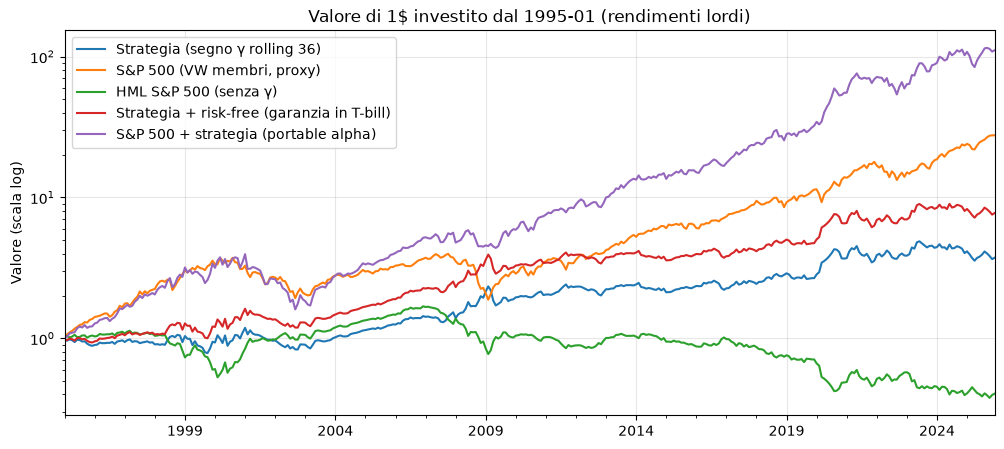

Valore finale di 1$:
Strategia (segno γ rolling 36)                  3.73
S&P 500 (VW membri, proxy)                     27.62
HML S&P 500 (senza γ)                           0.40
Strategia + risk-free (garanzia in T-bill)      7.75
S&P 500 + strategia (portable alpha)          110.95
Name: 2025-12, dtype: float64


In [14]:
# --- HML S&P 500 (senza γ) e allineamento delle date
base = a_periodi(serie_tutte["S&P 500"]["Senza γ"])
scala = 100 if base.abs().mean() > 0.2 else 1
base = base / scala

t_sp = pesi(crsp[crsp["sp500"].astype(bool)], False)
ls_mio = (t_sp["w"] * t_sp["ret_next"]).groupby(t_sp["mese"]).sum()
ls_sh = ls_mio.copy(); ls_sh.index = ls_sh.index + 1
off = 1 if ls_sh.corr(base) > ls_mio.corr(base) else 0

# --- S&P 500: media pesata per capitalizzazione dei membri (proxy dell'indice)
sp = crsp[crsp["sp500"].astype(bool)].dropna(subset=["MthCap", "ret_next"])
mkt = (sp["MthCap"] * sp["ret_next"]).groupby(sp["mese"]).sum() / sp["MthCap"].groupby(sp["mese"]).sum()
mkt.index = mkt.index + off

# --- strategia: segno del γ rolling 36 mesi
g = (a_periodi(serie_tutte["S&P 500"]["γ rolling 36 mesi"]) / scala / base).replace([np.inf, -np.inf], np.nan).ffill()
g = np.sign(g).replace(0, np.nan).ffill()
strat = g * base

# --- grafico cumulato
df = pd.concat({"Strategia (segno γ rolling 36)": strat,
                "S&P 500 (VW membri, proxy)": mkt,
                "HML S&P 500 (senza γ)": base}, axis=1).dropna()
df = df[df.index >= INIZIO]
rf = a_periodi(ff)["RF"]
rf = rf / 100 if rf.abs().mean() > 0.2 else rf
rf = rf.reindex(df.index)
df["Strategia + risk-free (garanzia in T-bill)"] = df["Strategia (segno γ rolling 36)"] + rf
df["S&P 500 + strategia (portable alpha)"] = df["S&P 500 (VW membri, proxy)"] + df["Strategia (segno γ rolling 36)"]
cum = (1 + df).cumprod()

ax = cum.plot(figsize=(12, 5), logy=True)
ax.set_title(f"Valore di 1$ investito dal {INIZIO} (rendimenti lordi)")
ax.set_ylabel("Valore (scala log)")
ax.set_xlabel("")
ax.grid(alpha=0.3)
plt.show()

print("Valore finale di 1$:")
print(cum.iloc[-1].round(2))

## Robustezza della versione 100/100 (S&P 500, segno del γ rolling 36)

1. **Ritardo extra:** il segno di γ è ritardato di un mese in più. Se i risultati restano simili, non c'è look-ahead.
2. **Senza crisi:** risultati escludendo 2008-09 e 2020.
3. **Solo tassi:** segno del γ rolling senza costante (nessun momentum del fattore).
4. **Sottoperiodi:** 1995-2009, 2010-21, 2022-25.
5. **Blocchi di 5 anni:** alpha nei 7 modelli.
6. **Portable alpha:** Sharpe dell'S&P 500 da solo contro S&P 500 + strategia.

In [15]:
y_sp = a_periodi(ls["S&P 500"])
segno = lambda g: np.sign(a_periodi(g)).replace(0, np.nan).ffill()
s_roll = segno(gamma_roll["S&P 500"])

def riga(nome, r):
    r = r[r.index >= INIZIO].dropna()
    a, t = alpha_mod(r, MODELLI_FATT["FF5+MOM"])
    return {"Versione": nome, "Mesi": len(r), "Rend. %/mese": f"{r.mean()*100:.2f}",
            "Sharpe": f"{sharpe(r):.2f}", "Drawdown": f"{drawdown_max(r)*100:.1f}%",
            "α FF5+MOM": f"{a*100:.2f} ({t:.2f})"}

base_r = (s_roll * y_sp).dropna()
crisi = base_r.index.year.isin([2008, 2009, 2020])

# --- 1-3: ritardo, crisi, solo tassi
test = [riga("Segno γ rolling (normale)", base_r),
        riga("Ritardo +1 mese", s_roll.shift(1) * y_sp),
        riga("Senza 2008-09 e 2020", base_r[~crisi])]
try:
    g_tassi = segno(gamma_rolling_senza_costante(ls["S&P 500"]))
    test.append(riga("Solo tassi (senza costante)", g_tassi * y_sp))
except Exception as e:
    print("Solo tassi non calcolato:", e)
print("1-3. Controlli di robustezza (dal 1995)")
display(pd.DataFrame(test).set_index("Versione"))

# --- 4: sottoperiodi
sotto = []
for a_, b_ in [("1995-01", "2009-12"), ("2010-01", "2021-12"), ("2022-01", "2025-12")]:
    r = base_r[(base_r.index >= pd.Period(a_, "M")) & (base_r.index <= pd.Period(b_, "M"))]
    sotto.append(riga(f"{a_[:4]}-{b_[:4]}", r))
print("\n4. Sottoperiodi")
display(pd.DataFrame(sotto).set_index("Versione"))

# --- 5: blocchi di 5 anni, 7 modelli
blocchi5 = [("1995", "1999"), ("2000", "2004"), ("2005", "2009"), ("2010", "2014"), ("2015", "2019"), ("2020", "2025")]
righe_b = []
for a_, b_ in blocchi5:
    r = base_r[(base_r.index.year >= int(a_)) & (base_r.index.year <= int(b_))]
    rb = {"Blocco": f"{a_}-{b_}"}
    for m, X in MODELLI_FATT.items():
        al, t = alpha_mod(r, X)
        rb[m] = f"{al*100:.2f} ({t:.2f})"
    righe_b.append(rb)
print("\n5. Alpha per blocchi di 5 anni (% mensile, t HAC)")
display(pd.DataFrame(righe_b).set_index("Blocco"))

# --- 6: portable alpha
d6 = pd.concat({"mkt": mkt, "rf": rf, "strat": strat}, axis=1).dropna()
d6 = d6[d6.index >= INIZIO]
ecc_sp = d6["mkt"] - d6["rf"]
ecc_comb = ecc_sp + d6["strat"]
print("\n6. Portable alpha (rendimenti in eccesso, dal 1995)")
print(f"Sharpe S&P 500:              {sharpe(ecc_sp):.2f}")
print(f"Sharpe S&P 500 + strategia:  {sharpe(ecc_comb):.2f}")
print(f"Correlazione strategia-S&P:  {d6['strat'].corr(d6['mkt']):.2f}")

1-3. Controlli di robustezza (dal 1995)


,Mesi,Rend. %/mese,Sharpe,Drawdown,α FF5+MOM
Versione,,,,,
Segno γ rolling (normale),372,0.44,0.36,-29.8%,0.59 (2.71)
Ritardo +1 mese,372,0.34,0.28,-60.9%,0.48 (1.96)
Senza 2008-09 e 2020,336,0.31,0.28,-29.8%,0.48 (2.18)
Solo tassi (senza costante),372,0.39,0.32,-40.0%,0.44 (1.80)



4. Sottoperiodi


,Mesi,Rend. %/mese,Sharpe,Drawdown,α FF5+MOM
Versione,,,,,
1995-2009,180,0.46,0.35,-29.8%,0.80 (2.70)
2010-2021,144,0.50,0.49,-23.4%,0.64 (2.14)
2022-2025,48,0.21,0.15,-27.2%,0.09 (0.17)



5. Alpha per blocchi di 5 anni (% mensile, t HAC)


,CAPM,FF3,FF3+MOM,FF5,FF5+MOM,Q,Q5
Blocco,,,,,,,
1995-1999,0.06 (0.14),0.25 (0.55),0.10 (0.21),0.43 (0.99),0.37 (0.75),0.86 (1.63),1.00 (1.95)
2000-2004,0.48 (1.09),-0.11 (-0.27),-0.21 (-0.61),0.66 (1.43),0.52 (1.44),0.46 (0.99),0.76 (1.38)
2005-2009,0.95 (3.21),0.98 (2.57),1.08 (2.68),1.04 (2.36),1.17 (2.32),0.78 (2.13),0.76 (1.48)
2010-2014,0.42 (1.05),0.41 (1.05),0.43 (1.06),0.51 (1.45),0.51 (1.42),0.69 (1.87),0.63 (1.81)
2015-2019,0.42 (1.45),0.25 (0.89),0.26 (0.93),0.31 (1.05),0.33 (1.15),0.38 (1.02),0.32 (0.97)
2020-2025,0.72 (0.98),0.55 (0.76),0.55 (0.74),0.58 (0.87),0.61 (0.89),0.48 (0.69),0.48 (0.70)



6. Portable alpha (rendimenti in eccesso, dal 1995)
Sharpe S&P 500:              0.60
Sharpe S&P 500 + strategia:  0.74
Correlazione strategia-S&P:  -0.12


## Prova: inflazione attesa (breakeven) nella regressione rolling

Breakeven a 10 anni = rendimento Treasury nominale (DGS10) − rendimento TIPS reale (DFII10) = inflazione attesa dal mercato.
Segnale: variazione a 3 mesi del breakeven, divisa per la volatilità dei 5 anni precedenti (come la variazione del 2 anni).

Confronto tre versioni del γ rolling 36 mesi (segno, portafoglio 100/100, S&P 500), sullo stesso periodo:
- **Base:** pendenza + variazione 2 anni (la versione attuale);
- **Base + breakeven:** aggiungo la variazione dell'inflazione attesa;
- **Solo breakeven.**

I dati TIPS partono dal 2003, quindi il confronto è dal primo mese disponibile per tutte e tre (circa 2006).


In [16]:
# --- breakeven = nominale - reale
nom, reale = fred("DGS10"), fred("DFII10")
breakeven = (nom - reale).dropna()
print("Breakeven disponibile da:", breakeven.index.min(),
      "| correlazione con T10YIE:", round(breakeven.corr(fred("T10YIE")), 3))
segnali["Variazione breakeven (3m)"] = z_variazione(breakeven.diff(3))

# --- regressione rolling generica: γ = segno della previsione
def gamma_segno_rolling(y, nomi, W=36):
    X = pd.concat({k: a_periodi(segnali[k]).shift(1) for k in nomi}, axis=1)
    d = pd.concat([a_periodi(y).rename("y"), X], axis=1).dropna()
    out = {}
    for i in range(W, len(d)):
        tr = d.iloc[i - W:i]
        fit = sm.OLS(tr["y"], sm.add_constant(tr[nomi])).fit()
        prev = fit.params["const"] + (fit.params[nomi] * d[nomi].iloc[i]).sum()
        out[d.index[i]] = np.sign(prev)
    return pd.Series(out).replace(0, np.nan).ffill()

y_sp = a_periodi(ls["S&P 500"])
BASE = ["Pendenza curva", "Variazione 2 anni (3m)"]
versioni = {"Base (pendenza + 2 anni)": BASE,
            "Base + breakeven": BASE + ["Variazione breakeven (3m)"],
            "Solo breakeven": ["Variazione breakeven (3m)"]}
g_ver = {n: gamma_segno_rolling(y_sp, v) for n, v in versioni.items()}

# controllo: la versione base deve coincidere con il segno del γ rolling del notebook
chk = pd.concat([g_ver["Base (pendenza + 2 anni)"], np.sign(a_periodi(gamma_roll["S&P 500"]))], axis=1).dropna()
print("Accordo con il γ rolling del notebook:", f"{(chk.iloc[:, 0] == chk.iloc[:, 1]).mean()*100:.0f}% dei mesi")

# --- stesso periodo per tutte
inizio = max(g.dropna().index.min() for g in g_ver.values())
ris = []
for n, g in g_ver.items():
    r = (g * y_sp).dropna()
    r = r[r.index >= inizio]
    riga_r = {"Versione": n, "Mesi": len(r), "Rend. %/mese": f"{r.mean()*100:.2f}",
              "Sharpe": f"{sharpe(r):.2f}", "Drawdown": f"{drawdown_max(r)*100:.1f}%",
              "Mesi long value": f"{(g.reindex(r.index) > 0).mean()*100:.0f}%"}
    for m, X in MODELLI_FATT.items():
        a, t = alpha_mod(r, X)
        riga_r[m] = f"{a*100:.2f} ({t:.2f})"
    ris.append(riga_r)

print(f"\nS&P 500, segno del γ rolling 36, dal {inizio} (alpha % mensile, t HAC)")
display(pd.DataFrame(ris).set_index("Versione"))


Breakeven disponibile da: 2003-01 | correlazione con T10YIE: 1.0
Accordo con il γ rolling del notebook: 100% dei mesi

S&P 500, segno del γ rolling 36, dal 2009-04 (alpha % mensile, t HAC)


,Mesi,Rend. %/mese,Sharpe,Drawdown,Mesi long value,CAPM,FF3,FF3+MOM,FF5,FF5+MOM,Q,Q5
Versione,,,,,,,,,,,,
Base (pendenza + 2 anni),201,0.35,0.30,-27.2%,41%,0.50 (1.58),0.44 (1.51),0.39 (1.27),0.44 (1.57),0.40 (1.33),0.38 (1.20),0.38 (1.29)
Base + breakeven,201,0.41,0.35,-25.8%,47%,0.55 (1.74),0.46 (1.51),0.43 (1.35),0.49 (1.69),0.47 (1.54),0.44 (1.41),0.46 (1.54)
Solo breakeven,201,0.26,0.23,-40.1%,30%,0.25 (0.73),0.13 (0.52),0.18 (0.67),0.11 (0.44),0.16 (0.59),0.19 (0.54),-0.04 (-0.16)


## Risultati finali: versione 100/100 dal primo mese disponibile

Il campione parte dal primo mese in cui il γ rolling è disponibile, non da una data scelta a mano:
- segnali FRED (pendenza 10–2 anni, tasso a 2 anni) dal 1976;
- 36 mesi per standardizzarli, poi 36 mesi per la prima regressione → primo γ a fine 1982.

Tutte le versioni sono confrontate sullo stesso periodo:
- **HML statico (senza γ):** sempre long value / short growth;
- **Segno γ fisso** e **segno γ rolling 36:** sempre 100% long e 100% short, il segno di γ decide la direzione.

Tabelle: **A.** lordo con alpha nei 7 modelli; **B.** turnover, costi e alpha netta FF5+MOM per V₀; **C.** alpha netta a $100M nei 7 modelli.

In [17]:
# ---------- campione: dal primo mese con γ rolling disponibile in tutti gli universi ----------
INIZIO = max(a_periodi(g).dropna().index.min() for g in gamma_roll.values())
print("Inizio campione:", INIZIO)

def segno(g):
    return np.sign(a_periodi(g)).replace(0, np.nan).ffill()

def nome_v0(V0):
    return f"${V0/1e6:,.0f}M" if V0 < 1e9 else f"${V0/1e9:,.0f}B"

VERSIONI_FIN = {"HML statico (senza γ)": None,
                "Segno γ fisso": gamma_fisso,
                "Segno γ rolling 36": "rolling"}

OFF, SERIE_FIN = {}, {}
righe_lordo, righe_costi, righe_netto100 = [], [], []

for u, (flag, bp_nyse) in UNIVERSI.items():
    c, ls_form = componenti(pesi(crsp[crsp[flag].astype(bool)], bp_nyse))   # indice = mese di formazione
    y_u = a_periodi(ls[u])                                                    # indice = mese di detenzione
    sh = ls_form.copy(); sh.index = sh.index + 1
    OFF[u] = 1 if sh.corr(y_u) > ls_form.corr(y_u) else 0
    print(f"{u}: correlazione pesi ricostruiti vs serie del notebook = {max(sh.corr(y_u), ls_form.corr(y_u)):.3f}")

    for v, g in VERSIONI_FIN.items():
        if g is None:
            s = pd.Series(1.0, index=y_u.index)
        elif isinstance(g, str):
            s = segno(gamma_roll[u])
        else:
            s = segno(g)
        r = (s * y_u).dropna()
        r = r[r.index >= INIZIO]

        # turnover e costi (segno riportato al mese di formazione)
        sf = s.copy(); sf.index = sf.index - OFF[u]
        gm = c["mese"].map(sf).fillna(0).to_numpy(dtype=float)
        gp = (c["mese"] - 1).map(sf).fillna(0).to_numpy(dtype=float)
        dw = np.abs(gm * c["w"].to_numpy() - gp * c["w_drift"].to_numpy())
        tmp = pd.DataFrame({"mese": c["mese"], "dw": dw,
                            "k": c["lam"].to_numpy() * dw**1.5 / np.sqrt(c["ADV"].to_numpy())})
        agg = tmp.groupby("mese")[["dw", "k"]].sum()
        agg.index = agg.index + OFF[u]
        K = agg["k"].reindex(r.index).fillna(0)
        turn = agg["dw"].reindex(r.index).fillna(0)
        SERIE_FIN[(u, v)] = (r, K, s)

        # A. lordo
        rl = {"Universo": u, "Versione": v, "Mesi": len(r),
              "Rend. %/mese": f"{r.mean()*100:.2f}", "Sharpe": f"{sharpe(r):.2f}",
              "Drawdown max": f"{drawdown_max(r)*100:.1f}%",
              "Mesi long value": f"{(s.reindex(r.index) > 0).mean()*100:.0f}%"}
        for m, X in MODELLI_FATT.items():
            a, t = alpha_mod(r, X)
            rl[m] = f"{a*100:.2f} ({t:.2f})"
        righe_lordo.append(rl)

        # B. turnover, costi e alpha netta FF5+MOM per ogni V0
        a_l, _ = alpha_mod(r, MODELLI_FATT["FF5+MOM"])
        a_k, _ = alpha_mod(K, MODELLI_FATT["FF5+MOM"])
        rc = {"Universo": u, "Versione": v, "Turnover %/mese": f"{turn.mean()*100:.0f}"}
        for V0 in V0_GRID:
            a_n, t_n = alpha_mod(r - np.sqrt(V0) * K, MODELLI_FATT["FF5+MOM"])
            rc[f"Costo {nome_v0(V0)}"] = f"{(np.sqrt(V0) * K).mean()*100:.2f}"
            rc[f"α netta {nome_v0(V0)}"] = f"{a_n*100:.2f} ({t_n:.2f})"
        rc["V0 pareggio ($M)"] = f"{(a_l / a_k) ** 2 / 1e6:,.0f}" if (a_l > 0 and a_k > 0) else "0"
        righe_costi.append(rc)

        # C. alpha netta a $100M nei 7 modelli
        rn = {"Universo": u, "Versione": v}
        for m, X in MODELLI_FATT.items():
            a, t = alpha_mod(r - np.sqrt(1e8) * K, X)
            rn[m] = f"{a*100:.2f} ({t:.2f})"
        righe_netto100.append(rn)

pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
idx = ["Universo", "Versione"]
print(f"\nA. Versione 100/100, lordo, dal {INIZIO} (alpha % mensile, t HAC)")
display(pd.DataFrame(righe_lordo).set_index(idx))
print(f"\nB. Turnover, costi (%/mese) e alpha netta FF5+MOM, dal {INIZIO}")
display(pd.DataFrame(righe_costi).set_index(idx))
print(f"\nC. Alpha netta a V0 = $100M nei 7 modelli, dal {INIZIO}")
display(pd.DataFrame(righe_netto100).set_index(idx))

Inizio campione: 1982-09
S&P 500: correlazione pesi ricostruiti vs serie del notebook = 1.000
NYSE/AMEX/NASDAQ: correlazione pesi ricostruiti vs serie del notebook = 1.000
NYSE/AMEX/NASDAQ (breakpoint NYSE): correlazione pesi ricostruiti vs serie del notebook = 1.000

A. Versione 100/100, lordo, dal 1982-09 (alpha % mensile, t HAC)


Mesi Rend. %/mese Sharpe Drawdown max Mesi long value           CAPM            FF3        FF3+MOM            FF5        FF5+MOM              Q           Q5
Universo                           Versione                                                                                                                                                                           
S&P 500                            HML statico (senza γ)   520         0.01   0.01       -77.6%            100%  -0.01 (-0.05)  -0.29 (-2.82)  -0.06 (-0.64)  -0.21 (-1.77)  -0.02 (-0.26)  -0.11 (-0.61)  0.08 (0.50)
                                   Segno γ fisso           520         0.35   0.31       -59.9%             50%    0.31 (1.51)    0.34 (1.76)    0.39 (1.79)    0.44 (2.29)    0.47 (2.26)    0.48 (2.30)  0.31 (1.50)
                                   Segno γ rolling 36      520         0.26   0.23       -47.2%             57%    0.32 (1.88)    0.37 (2.14)    0.32 (1.80)    0.43 (2.45)    0.39 (2.12)    0.39 (1.99)  0.40 (2.13)
NYSE/AMEX/NASDAQ                   HML statico (senza γ)   520         0.12   0.09       -66.6%            100%    0.01 (0.04)  -0.27 (-2.22)    0.09 (0.79)  -0.06 (-0.42)    0.22 (2.03)    0.10 (0.43)  0.28 (1.38)
                                   Segno γ fisso           520         0.32   0.27       -68.6%             50%    0.29 (1.35)    0.28 (1.30)    0.34 (1.24)    0.39 (1.80)    0.44 (1.65)    0.42 (1.63)  0.27 (1.05)
                                   Segno γ rolling 36      520         0.28   0.23       -54.5%             56%    0.39 (2.07)    0.42 (2.14)    0.23 (1.03)    0.34 (1.66)    0.19 (0.88)    0.26 (1.04)  0.35 (1.43)
NYSE/AMEX/NASDAQ (breakpoint NYSE) HML statico (senza γ)   520         0.08   0.08       -67.7%            100%    0.01 (0.05)  -0.25 (-2.71)    0.04 (0.52)  -0.10 (-0.90)    0.13 (1.60)    0.03 (0.13)  0.21 (1.26)
                                   Segno γ fisso           520         0.34   0.31       -58.0%             50%    0.32 (1.63)    0.32 (1.70)    0.36 (1.56)    0.40 (2.09)    0.43 (1.93)    0.43 (1.98)  0.29 (1.30)
                                   Segno γ rolling 36      520         0.26   0.24       -44.6%             57%    0.36 (2.07)    0.39 (2.11)    0.24 (1.17)    0.37 (1.99)    0.25 (1.28)    0.28 (1.30)  0.35 (1.66)


B. Turnover, costi (%/mese) e alpha netta FF5+MOM, dal 1982-09


Turnover %/mese Costo $10M   α netta $10M Costo $100M  α netta $100M Costo $1B    α netta $1B Costo $10B   α netta $10B V0 pareggio ($M)
Universo                           Versione                                                                                                                                                      
S&P 500                            HML statico (senza γ)              26       0.01  -0.04 (-0.40)        0.04  -0.06 (-0.71)      0.13  -0.15 (-1.70)       0.40  -0.41 (-4.55)                0
                                   Segno γ fisso                      82       0.05    0.43 (2.04)        0.15    0.33 (1.56)      0.48    0.02 (0.07)       1.52  -0.98 (-3.36)            1,071
                                   Segno γ rolling 36                 92       0.06    0.33 (1.79)        0.18    0.21 (1.10)      0.56  -0.17 (-0.76)       1.79  -1.37 (-3.81)              484
NYSE/AMEX/NASDAQ                   HML statico (senza γ)              33       0.02    0.19 (1.85)        0.07    0.15 (1.45)      0.21    0.01 (0.13)       0.66  -0.42 (-4.04)            1,134
                                   Segno γ fisso                      88       0.06    0.37 (1.41)        0.20    0.24 (0.91)      0.63  -0.18 (-0.64)       1.98  -1.50 (-4.10)              505
                                   Segno γ rolling 36                109       0.08    0.11 (0.51)        0.25  -0.06 (-0.24)      0.80  -0.59 (-2.22)       2.52  -2.27 (-5.37)               60
NYSE/AMEX/NASDAQ (breakpoint NYSE) HML statico (senza γ)              29       0.02    0.11 (1.41)        0.05    0.08 (0.98)      0.16  -0.03 (-0.43)       0.52  -0.38 (-4.70)              633
                                   Segno γ fisso                      84       0.05    0.38 (1.69)        0.17    0.27 (1.18)      0.54  -0.09 (-0.38)       1.70  -1.22 (-3.90)              685
                                   Segno γ rolling 36                 99       0.07    0.19 (0.94)        0.21    0.05 (0.24)      0.66  -0.39 (-1.68)       2.09  -1.78 (-4.84)              153


C. Alpha netta a V0 = $100M nei 7 modelli, dal 1982-09


CAPM            FF3        FF3+MOM            FF5        FF5+MOM              Q           Q5
Universo                           Versione                                                                                                                    
S&P 500                            HML statico (senza γ)  -0.05 (-0.23)  -0.33 (-3.22)  -0.10 (-1.09)  -0.25 (-2.11)  -0.06 (-0.71)  -0.15 (-0.82)  0.05 (0.28)
                                   Segno γ fisso            0.16 (0.78)    0.19 (0.98)    0.24 (1.11)    0.29 (1.51)    0.33 (1.56)    0.34 (1.60)  0.17 (0.83)
                                   Segno γ rolling 36       0.14 (0.78)    0.20 (1.07)    0.14 (0.77)    0.25 (1.37)    0.21 (1.10)    0.22 (1.06)  0.23 (1.19)
NYSE/AMEX/NASDAQ                   HML statico (senza γ)  -0.06 (-0.25)  -0.33 (-2.77)    0.02 (0.20)  -0.12 (-0.88)    0.15 (1.45)    0.04 (0.16)  0.22 (1.09)
                                   Segno γ fisso            0.10 (0.44)    0.08 (0.38)    0.15 (0.53)    0.19 (0.88)    0.24 (0.91)    0.23 (0.88)  0.09 (0.33)
                                   Segno γ rolling 36       0.14 (0.68)    0.17 (0.80)  -0.02 (-0.10)    0.09 (0.41)  -0.06 (-0.24)    0.02 (0.06)  0.12 (0.45)
NYSE/AMEX/NASDAQ (breakpoint NYSE) HML statico (senza γ)  -0.04 (-0.20)  -0.31 (-3.27)  -0.01 (-0.14)  -0.15 (-1.34)    0.08 (0.98)  -0.02 (-0.12)  0.17 (0.98)
                                   Segno γ fisso            0.15 (0.76)    0.15 (0.80)    0.20 (0.84)    0.23 (1.20)    0.27 (1.18)    0.27 (1.23)  0.13 (0.58)
                                   Segno γ rolling 36       0.15 (0.81)    0.18 (0.92)    0.03 (0.13)    0.16 (0.84)    0.05 (0.24)    0.08 (0.36)  0.16 (0.73)

### Zoom sul periodo 1982–1994

Perché il timing funziona meno prima del 1995? Per ogni versione (HML statico, segno γ fisso, segno γ rolling 36):
- statistiche e alpha nei 7 modelli solo su 1982-09 → 1994-12;
- quota di mesi long value, cambi di segno e mesi "indovinati" (rendimento della strategia > 0);
- rendimento anno per anno e grafico cumulato sull'S&P 500.

1. Dal 1982-09 al 1994-12 (alpha % mensile, t HAC)


Mesi Rend. %/mese Sharpe Drawdown Mesi long value  Cambi di segno Mesi indovinati           CAPM            FF3        FF3+MOM            FF5        FF5+MOM              Q             Q5
Universo                           Versione                                                                                                                                                                                                         
S&P 500                            HML statico (senza γ)   148         0.43   0.56   -28.8%            100%               0             56%    0.50 (1.84)    0.02 (0.11)    0.28 (2.20)    0.29 (1.70)    0.43 (2.67)    0.81 (3.20)    0.64 (2.60)
                                   Segno γ fisso           148         0.41   0.52   -26.3%             68%              20             59%    0.47 (1.90)    0.28 (1.26)    0.22 (0.92)    0.39 (1.63)    0.35 (1.35)    0.21 (0.71)  -0.03 (-0.11)
                                   Segno γ rolling 36      148        -0.20  -0.26   -41.1%             68%              27             50%  -0.21 (-0.97)  -0.27 (-1.50)  -0.33 (-1.44)  -0.14 (-0.59)  -0.19 (-0.72)  -0.34 (-1.07)  -0.44 (-1.41)
NYSE/AMEX/NASDAQ                   HML statico (senza γ)   148         0.32   0.37   -38.8%            100%               0             53%    0.42 (1.29)  -0.14 (-0.83)    0.19 (1.70)    0.11 (0.64)    0.28 (2.17)    0.83 (2.73)    0.61 (2.20)
                                   Segno γ fisso           148         0.42   0.49   -27.9%             68%              20             54%    0.54 (1.97)    0.34 (1.31)    0.28 (1.09)    0.38 (1.46)    0.35 (1.28)    0.26 (0.91)    0.02 (0.08)
                                   Segno γ rolling 36      148        -0.11  -0.12   -40.9%             64%              26             50%  -0.15 (-0.53)  -0.16 (-0.64)  -0.38 (-1.35)  -0.09 (-0.33)  -0.22 (-0.77)  -0.41 (-1.10)  -0.31 (-0.93)
NYSE/AMEX/NASDAQ (breakpoint NYSE) HML statico (senza γ)   148         0.32   0.42   -34.9%            100%               0             51%    0.41 (1.41)  -0.10 (-0.66)    0.20 (1.81)    0.18 (1.20)    0.33 (2.70)    0.75 (2.72)    0.59 (2.28)
                                   Segno γ fisso           148         0.38   0.49   -28.7%             68%              20             53%    0.49 (1.98)    0.31 (1.40)    0.26 (1.13)    0.38 (1.62)    0.35 (1.38)    0.24 (0.90)    0.05 (0.18)
                                   Segno γ rolling 36      148        -0.20  -0.26   -44.6%             66%              28             47%  -0.21 (-0.83)  -0.30 (-1.33)  -0.46 (-1.80)  -0.27 (-1.02)  -0.36 (-1.33)  -0.44 (-1.34)  -0.55 (-1.70)


2. S&P 500: rendimento annuo (%) e quota di mesi long value (%)


,HML statico (senza γ),Segno γ fisso,Segno γ rolling 36,Mesi long value – γ fisso,Mesi long value – γ rolling 36
1982,-1.7,6.7,2.5,50.0,25.0
1983,29.0,29.0,-15.9,100.0,25.0
1984,14.0,1.3,14.0,75.0,100.0
1985,-2.5,-2.5,-2.5,100.0,100.0
1986,0.5,-7.5,-10.9,33.3,50.0
1987,-0.1,-0.1,-9.4,100.0,58.3
1988,16.2,-5.1,-8.2,33.3,41.7
1989,-10.4,11.1,5.2,0.0,33.3
1990,-12.7,14.4,-6.6,16.7,75.0
1991,0.3,-13.9,0.3,83.3,100.0


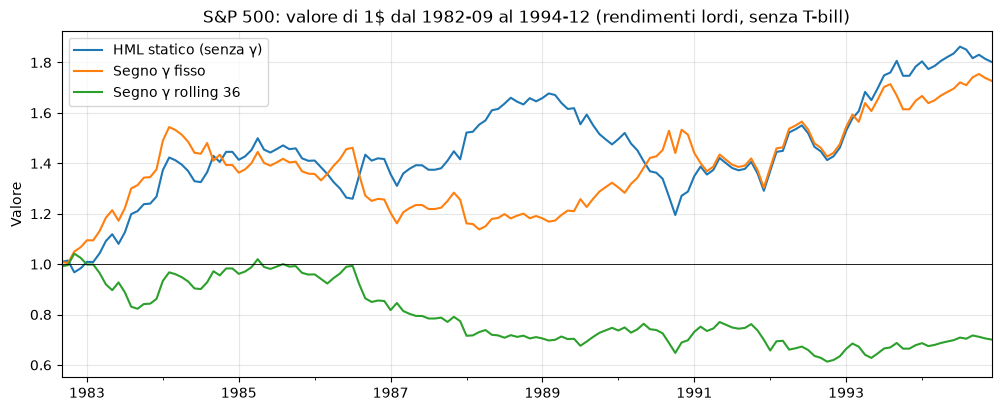

In [18]:
A_Z, B_Z = INIZIO, pd.Period("1994-12", "M")
VERS = ["HML statico (senza γ)", "Segno γ fisso", "Segno γ rolling 36"]

# ---------- 1. statistiche e alpha, 1982-1994 ----------
righe_z = []
for u in UNIVERSI:
    for v in VERS:
        r, K, s = SERIE_FIN[(u, v)]
        r = r[(r.index >= A_Z) & (r.index <= B_Z)]
        ss = s.reindex(r.index)
        rz = {"Universo": u, "Versione": v, "Mesi": len(r),
              "Rend. %/mese": f"{r.mean()*100:.2f}", "Sharpe": f"{sharpe(r):.2f}",
              "Drawdown": f"{drawdown_max(r)*100:.1f}%",
              "Mesi long value": f"{(ss > 0).mean()*100:.0f}%",
              "Cambi di segno": int((ss.diff().abs() > 0).sum()),
              "Mesi indovinati": f"{(r > 0).mean()*100:.0f}%"}
        for m, X in MODELLI_FATT.items():
            a, t = alpha_mod(r, X)
            rz[m] = f"{a*100:.2f} ({t:.2f})"
        righe_z.append(rz)
print(f"1. Dal {A_Z} al {B_Z} (alpha % mensile, t HAC)")
display(pd.DataFrame(righe_z).set_index(["Universo", "Versione"]))

# ---------- 2. S&P 500 anno per anno ----------
U = "S&P 500"
serie_z = {v: SERIE_FIN[(U, v)][0] for v in VERS}
tab = pd.concat(serie_z, axis=1)
tab = tab[(tab.index >= A_Z) & (tab.index <= B_Z)]
annuo = tab.groupby(tab.index.year).apply(lambda g: (1 + g).prod() - 1) * 100
for v in ["Segno γ fisso", "Segno γ rolling 36"]:
    s = SERIE_FIN[(U, v)][2].reindex(tab.index)
    annuo[f"Mesi long value – {v.replace('Segno ', '')}"] = (s > 0).groupby(tab.index.year).mean() * 100
print(f"\n2. {U}: rendimento annuo (%) e quota di mesi long value (%)")
display(annuo.round(1))

# ---------- 3. grafico cumulato 1982-1994 ----------
cum_z = (1 + tab).cumprod()
ax = cum_z.plot(figsize=(12, 4.5))
ax.axhline(1, color="black", lw=0.6)
ax.set_title(f"{U}: valore di 1$ dal {A_Z} al {B_Z} (rendimenti lordi, senza T-bill)")
ax.set_ylabel("Valore"); ax.set_xlabel(""); ax.grid(alpha=0.3)
plt.show()

### Test: la strategia funziona peggio quando i tassi sono molto volatili?

Ipotesi: nel 1982–94 la rolling ha fallito perché la volatilità dei tassi era altissima (era Volcker).
Lo verifico su tutto il campione, non solo sugli anni '80:
- volatilità = deviazione standard delle variazioni mensili del tasso a 2 anni (DGS2) nei 12 mesi precedenti, quindi nota al momento della formazione;
- divido i mesi in tre gruppi uguali: volatilità bassa, media, alta;
- per ogni gruppo: rendimento, Sharpe, mesi indovinati, alpha FF5+MOM; poi la differenza alta − bassa con t HAC.

Le soglie dei gruppi sono calcolate sull'intero campione: è un test descrittivo, non una regola di trading.
Controllo anche in quali decenni cadono i mesi ad alta volatilità, e ripeto il test solo dal 1995:
se il risultato regge senza gli anni '80, non dipende solo da quel decennio.

In [19]:
# ---------- volatilità del tasso a 2 anni nei 12 mesi precedenti (nota al momento della formazione) ----------
dgs2 = a_periodi(fred("DGS2"))
vol2 = dgs2.diff().rolling(12).std()
vol2.index = vol2.index + 1            # indice = mese di detenzione: usa solo dati fino al mese prima

U = "S&P 500"
VERS = ["HML statico (senza γ)", "Segno γ fisso", "Segno γ rolling 36"]
GRUPPI = ["Bassa", "Media", "Alta"]

d_v = pd.concat({v: SERIE_FIN[(U, v)][0] for v in VERS}, axis=1)
d_v["vol"] = vol2
d_v = d_v.dropna()
d_v["gruppo"] = pd.qcut(d_v["vol"], 3, labels=GRUPPI)
soglie = d_v.groupby("gruppo", observed=True)["vol"].agg(["min", "max"])
print("Soglie di volatilità (punti % al mese):")
display(soglie.round(2))

def tabella_vol(dati, titolo):
    righe = []
    for v in VERS:
        for gname in GRUPPI:
            r = dati.loc[dati["gruppo"] == gname, v]
            if len(r) < 24:
                continue
            a, t = alpha_mod(r, MODELLI_FATT["FF5+MOM"])
            righe.append({"Versione": v, "Volatilità tassi": gname, "Mesi": len(r),
                          "Rend. %/mese": f"{r.mean()*100:.2f}", "Sharpe": f"{sharpe(r):.2f}",
                          "Mesi indovinati": f"{(r > 0).mean()*100:.0f}%",
                          "α FF5+MOM": f"{a*100:.2f} ({t:.2f})"})
        # differenza di rendimento alta - bassa volatilità (t HAC)
        x = dati[dati["gruppo"].isin(["Bassa", "Alta"])]
        dummy = (x["gruppo"] == "Alta").astype(float).rename("alta")
        fit = sm.OLS(x[v], sm.add_constant(dummy)).fit(cov_type="HAC", cov_kwds={"maxlags": LAG_HAC})
        righe.append({"Versione": v, "Volatilità tassi": "Alta − Bassa", "Mesi": len(x),
                      "Rend. %/mese": f"{fit.params['alta']*100:.2f} (t {fit.tvalues['alta']:.2f})"})
    print(f"\n{titolo}")
    display(pd.DataFrame(righe).set_index(["Versione", "Volatilità tassi"]).fillna(""))

# ---------- 1. tutto il campione ----------
tabella_vol(d_v, f"1. {U}, dal {d_v.index.min()}: rendimento per livello di volatilità dei tassi")

# ---------- 2. dove cadono i mesi ad alta volatilità ----------
print("\n2. Numero di mesi per decennio e gruppo di volatilità")
display(pd.crosstab((d_v.index.year // 10) * 10, d_v["gruppo"]).rename_axis("Decennio"))

# ---------- 3. stesso test senza 1982-1994 (stesse soglie) ----------
tabella_vol(d_v[d_v.index >= pd.Period("1995-01", "M")],
            f"3. {U}, solo dal 1995 (soglie di volatilità dell'intero campione)")

Soglie di volatilità (punti % al mese):


,min,max
gruppo,,
Bassa,0.03,0.20
Media,0.20,0.32
Alta,0.32,1.15



1. S&P 500, dal 1982-09: rendimento per livello di volatilità dei tassi


Mesi     Rend. %/mese Sharpe Mesi indovinati      α FF5+MOM
Versione              Volatilità tassi                                                             
HML statico (senza γ) Bassa              174            -0.27  -0.25             44%  -0.12 (-0.84)
                      Media              173             0.33   0.28             58%    0.08 (0.51)
                      Alta               173            -0.01  -0.01             52%  -0.08 (-0.51)
                      Alta − Bassa       347    0.26 (t 0.61)                                      
Segno γ fisso         Bassa              174            -0.29  -0.27             48%  -0.37 (-1.22)
                      Media              173             0.59   0.52             56%    0.71 (2.05)
                      Alta               173             0.75   0.68             58%    0.99 (3.18)
                      Alta − Bassa       347    1.04 (t 2.74)                                      
Segno γ rolling 36    Bassa              174             0.43   0.39             56%    0.73 (2.86)
                      Media              173             0.45   0.39             58%    0.44 (1.47)
                      Alta               173            -0.10  -0.09             47%    0.11 (0.32)
                      Alta − Bassa       347  -0.52 (t -1.27)


2. Numero di mesi per decennio e gruppo di volatilità


gruppo,Bassa,Media,Alta
Decennio,,,
1980,0,6,82
1990,14,68,38
2000,34,51,35
2010,109,11,0
2020,17,37,18



3. S&P 500, solo dal 1995 (soglie di volatilità dell'intero campione)


Mesi     Rend. %/mese Sharpe Mesi indovinati      α FF5+MOM
Versione              Volatilità tassi                                                             
HML statico (senza γ) Bassa              166            -0.25  -0.22             44%  -0.16 (-1.13)
                      Media              137             0.22   0.18             57%    0.10 (0.62)
                      Alta                69            -0.67  -0.46             46%  -0.13 (-0.52)
                      Alta − Bassa       235  -0.42 (t -0.68)                                      
Segno γ fisso         Bassa              166            -0.27  -0.25             49%  -0.38 (-1.21)
                      Media              137             0.66   0.54             56%    0.70 (1.60)
                      Alta                69             1.07   0.75             54%    0.97 (2.31)
                      Alta − Bassa       235    1.34 (t 2.34)                                      
Segno γ rolling 36    Bassa              166             0.48   0.44             57%    0.76 (2.92)
                      Media              137             0.56   0.46             60%    0.55 (1.57)
                      Alta                69             0.12   0.08             43%  -0.05 (-0.11)
                      Alta − Bassa       235  -0.37 (t -0.52)

### Versione combinata: γ fisso quando i tassi sono volatili, γ rolling quando sono calmi (esplorativa)

Dal test precedente: il γ fisso funziona con volatilità dei tassi alta, il rolling con volatilità bassa.
Regola implementabile in tempo reale, senza informazione futura:
- volatilità = deviazione standard delle variazioni mensili del tasso a 2 anni nei 12 mesi precedenti;
- soglia = mediana di tutta la storia di questa volatilità disponibile fino a quel mese (finestra crescente, almeno 5 anni);
- volatilità sopra la soglia → segno del γ fisso; sotto → segno del γ rolling 36. Sempre 100% long e 100% short.

**Attenzione:** la regola è stata ideata dopo aver visto i risultati del test sulla volatilità,
quindi è un'analisi esplorativa e non la strategia principale.

Mesi con volatilità alta (uso il γ fisso): 16%

1. S&P 500, dal 1982-09 (alpha % mensile, t HAC)


,Mesi,Rend. %/mese,Sharpe,Drawdown,Turnover %/mese,CAPM,FF3,FF3+MOM,FF5,FF5+MOM,Q,Q5,α netta FF5+MOM $100M,α netta FF5+MOM $1B
Versione,,,,,,,,,,,,,,
HML statico (senza γ),520,0.01,0.01,-77.6%,26,-0.01 (-0.05),-0.29 (-2.82),-0.06 (-0.64),-0.21 (-1.77),-0.02 (-0.26),-0.11 (-0.61),0.08 (0.50),-0.06 (-0.71),-0.15 (-1.70)
Segno γ fisso,520,0.35,0.31,-59.9%,82,0.31 (1.51),0.34 (1.76),0.39 (1.79),0.44 (2.29),0.47 (2.26),0.48 (2.30),0.31 (1.50),0.33 (1.56),0.02 (0.07)
Segno γ rolling 36,520,0.26,0.23,-47.2%,92,0.32 (1.88),0.37 (2.14),0.32 (1.80),0.43 (2.45),0.39 (2.12),0.39 (1.99),0.40 (2.13),0.21 (1.10),-0.17 (-0.76)
"Combinata (fisso se vol. alta, rolling se bassa)",520,0.33,0.30,-49.4%,97,0.34 (2.02),0.36 (2.10),0.43 (2.43),0.50 (2.89),0.55 (3.05),0.51 (2.76),0.43 (2.50),0.36 (1.88),-0.04 (-0.19)



2. Alpha FF5+MOM per sottoperiodo (% mensile, t HAC)


,1982-1994,1995-2009,2010-2021,2022-2025
Versione,,,,
HML statico (senza γ),0.43 (2.67),-0.11 (-0.61),-0.08 (-0.67),-0.35 (-1.43)
Segno γ fisso,0.35 (1.35),0.40 (0.92),0.29 (0.77),0.53 (1.09)
Segno γ rolling 36,-0.19 (-0.72),0.80 (2.70),0.64 (2.14),0.09 (0.17)
"Combinata (fisso se vol. alta, rolling se bassa)",-0.16 (-0.56),0.80 (2.76),0.64 (2.14),0.62 (1.33)


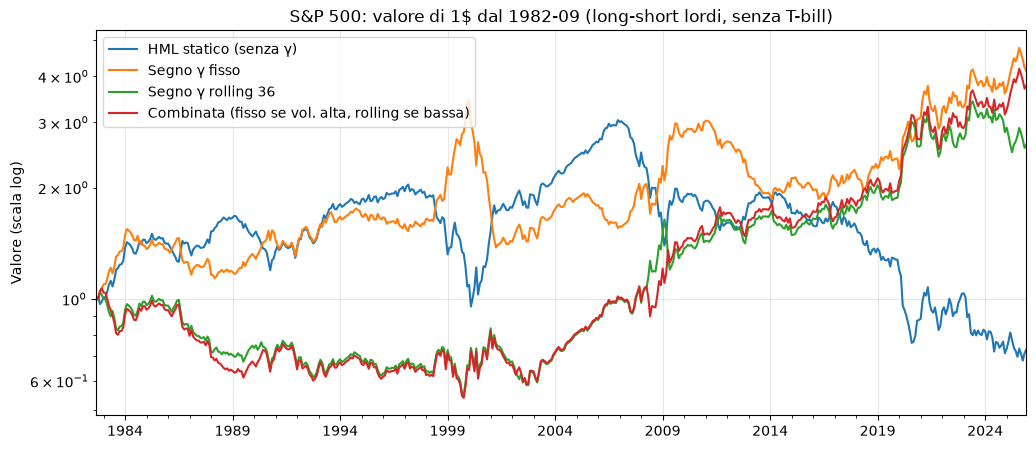

In [20]:
U = "S&P 500"
y_sp = a_periodi(ls[U])

# ---------- 1. regime di volatilità in tempo reale ----------
dgs2 = a_periodi(fred("DGS2"))
vol2 = dgs2.diff().rolling(12).std()
vol2.index = vol2.index + 1                                # indice = mese di detenzione (dati fino al mese prima)
soglia = vol2.expanding(min_periods=60).median()           # mediana di tutta la storia disponibile fino a quel mese
alta = (vol2 > soglia).astype(float)
alta[soglia.isna()] = np.nan

# ---------- 2. segno combinato: fisso se volatilità alta, rolling se bassa ----------
s_fis = SERIE_FIN[(U, "Segno γ fisso")][2]
s_rol = SERIE_FIN[(U, "Segno γ rolling 36")][2]
idx_c = s_rol.index
alta_c = alta.reindex(idx_c)
s_comb = pd.Series(np.where(alta_c == 1, s_fis.reindex(idx_c), s_rol), index=idx_c)
s_comb[alta_c.isna() | s_fis.reindex(idx_c).isna()] = np.nan

# ---------- 3. rendimenti, turnover e costi ----------
c_sp, _ = componenti(pesi(crsp[crsp["sp500"].astype(bool)], False))

def rend_costi(s):
    r = (s * y_sp).dropna()
    r = r[r.index >= INIZIO]
    sf = s.copy(); sf.index = sf.index - OFF[U]
    gm = c_sp["mese"].map(sf).fillna(0).to_numpy(dtype=float)
    gp = (c_sp["mese"] - 1).map(sf).fillna(0).to_numpy(dtype=float)
    dw = np.abs(gm * c_sp["w"].to_numpy() - gp * c_sp["w_drift"].to_numpy())
    tmp = pd.DataFrame({"mese": c_sp["mese"], "dw": dw,
                        "k": c_sp["lam"].to_numpy() * dw**1.5 / np.sqrt(c_sp["ADV"].to_numpy())})
    agg = tmp.groupby("mese")[["dw", "k"]].sum()
    agg.index = agg.index + OFF[U]
    return r, agg["k"].reindex(r.index).fillna(0), agg["dw"].reindex(r.index).fillna(0)

VERS_C = {"HML statico (senza γ)": pd.Series(1.0, index=y_sp.index),
          "Segno γ fisso": s_fis,
          "Segno γ rolling 36": s_rol,
          "Combinata (fisso se vol. alta, rolling se bassa)": s_comb}

righe_c, serie_c = [], {}
for v, s in VERS_C.items():
    r, K, turn = rend_costi(s)
    serie_c[v] = r
    rc = {"Versione": v, "Mesi": len(r), "Rend. %/mese": f"{r.mean()*100:.2f}",
          "Sharpe": f"{sharpe(r):.2f}", "Drawdown": f"{drawdown_max(r)*100:.1f}%",
          "Turnover %/mese": f"{turn.mean()*100:.0f}"}
    for m, X in MODELLI_FATT.items():
        a, t = alpha_mod(r, X)
        rc[m] = f"{a*100:.2f} ({t:.2f})"
    for V0 in [1e8, 1e9]:
        a, t = alpha_mod(r - np.sqrt(V0) * K, MODELLI_FATT["FF5+MOM"])
        rc[f"α netta FF5+MOM {nome_v0(V0)}"] = f"{a*100:.2f} ({t:.2f})"
    righe_c.append(rc)

print(f"Mesi con volatilità alta (uso il γ fisso): {alta_c[alta_c.index >= INIZIO].mean()*100:.0f}%")
print(f"\n1. {U}, dal {INIZIO} (alpha % mensile, t HAC)")
display(pd.DataFrame(righe_c).set_index("Versione"))

# ---------- 4. sottoperiodi ----------
periodi_c = [(INIZIO, pd.Period("1994-12", "M")), (pd.Period("1995-01", "M"), pd.Period("2009-12", "M")),
             (pd.Period("2010-01", "M"), pd.Period("2021-12", "M")), (pd.Period("2022-01", "M"), y_sp.index.max())]
righe_p = []
for v, r in serie_c.items():
    rp = {"Versione": v}
    for a_, b_ in periodi_c:
        x = r[(r.index >= a_) & (r.index <= b_)]
        a, t = alpha_mod(x, MODELLI_FATT["FF5+MOM"])
        rp[f"{a_.year}-{b_.year}"] = f"{a*100:.2f} ({t:.2f})"
    righe_p.append(rp)
print("\n2. Alpha FF5+MOM per sottoperiodo (% mensile, t HAC)")
display(pd.DataFrame(righe_p).set_index("Versione"))

# ---------- 5. grafico cumulato ----------
cum_c = (1 + pd.concat(serie_c, axis=1).dropna()).cumprod()
ax = cum_c.plot(figsize=(12, 5), logy=True)
ax.set_title(f"{U}: valore di 1$ dal {INIZIO} (long-short lordi, senza T-bill)")
ax.set_ylabel("Valore (scala log)"); ax.set_xlabel(""); ax.grid(alpha=0.3)
plt.show()

### Rendimenti rolling

Per ogni versione (HML statico, segno γ fisso, segno γ rolling 36, combinata), su una finestra mobile di 36 mesi:
- rendimento medio annualizzato;
- Sharpe annualizzato.

Le bande grigie indicano i mesi con volatilità dei tassi alta (sopra la mediana storica disponibile fino a quel mese),
per vedere in quali regimi ciascuna versione guadagna o perde.

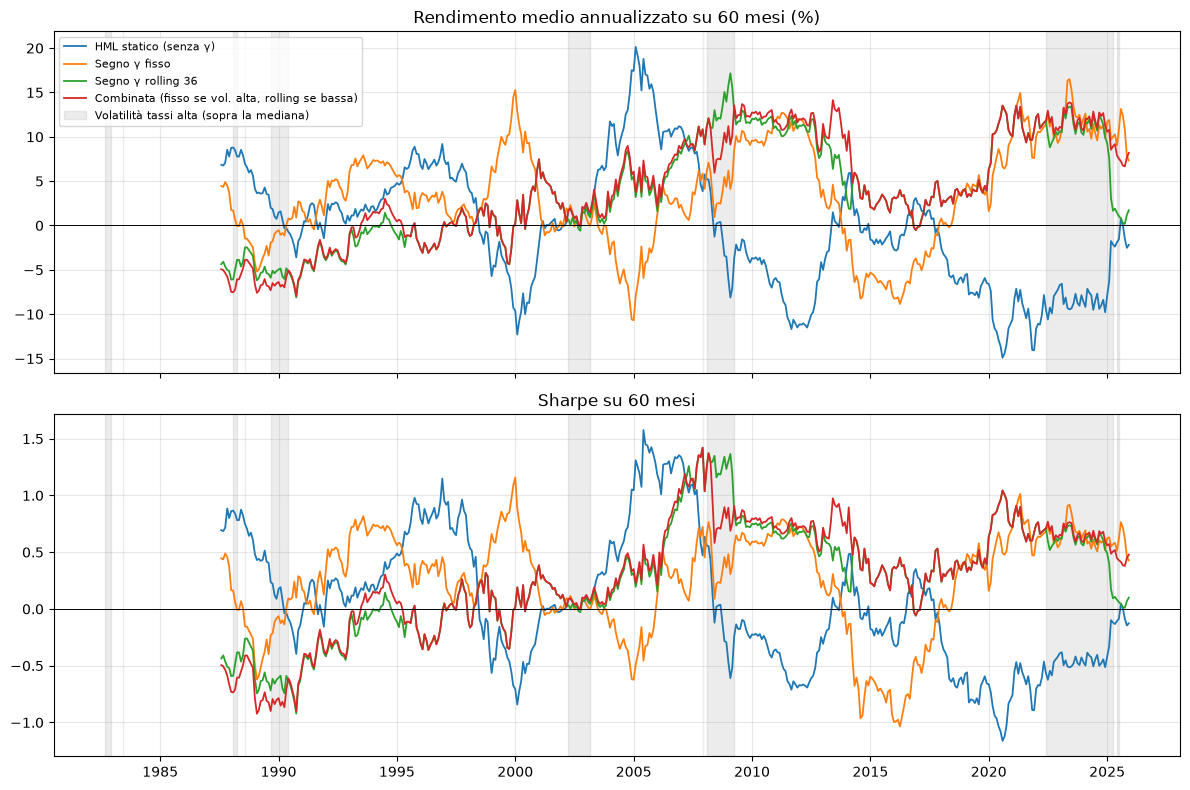

In [21]:
FINESTRA = 60                                            # mesi della finestra mobile

dati_r = pd.concat(serie_c, axis=1).dropna()
media_r = dati_r.rolling(FINESTRA).mean() * 12 * 100                                   # rendimento medio annualizzato (%)
sharpe_r = dati_r.rolling(FINESTRA).mean() / dati_r.rolling(FINESTRA).std() * np.sqrt(12)
x = dati_r.index.to_timestamp()
regime = alta.reindex(dati_r.index).fillna(0).to_numpy() == 1

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for ax, tab, titolo in [(axes[0], media_r, f"Rendimento medio annualizzato su {FINESTRA} mesi (%)"),
                        (axes[1], sharpe_r, f"Sharpe su {FINESTRA} mesi")]:
    for col in tab.columns:
        ax.plot(x, tab[col], label=col, lw=1.3)
    ax.fill_between(x, 0, 1, where=regime, transform=ax.get_xaxis_transform(),
                    color="grey", alpha=0.15, label="Volatilità tassi alta (sopra la mediana)")
    ax.axhline(0, color="black", lw=0.7)
    ax.set_title(titolo); ax.grid(alpha=0.3)
axes[0].legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

### Ribilanciamento meno frequente per ridurre i costi

Il turnover mensile (80–90%) dimezza l'alpha già a $100M. Riduco gli scambi mantenendo il vincolo 100/100:
- ribilancio solo ogni H mesi: trimestrale (fine marzo, giugno, settembre, dicembre) o semestrale (fine giugno e dicembre);
- al ribilanciamento: nuovi terzili di B/M, nuovi pesi per capitalizzazione e nuovo segno di γ, deciso con i dati disponibili in quel momento;
- tra un ribilanciamento e l'altro il portafoglio resta fermo (buy-and-hold) e i pesi si muovono solo con i prezzi;
- se un titolo esce dal mercato (delisting), il ricavato viene reinvestito nella sua gamba.

**Scelta fissata prima di vedere i risultati:** il trimestrale è la versione principale, il semestrale serve come controllo di sensibilità.
Il mensile è ricalcolato con lo stesso codice come verifica: deve coincidere con i risultati finali.

In [22]:
U = "S&P 500"
FREQUENZE = {1: "Mensile", 3: "Trimestrale", 6: "Semestrale"}
VERS_H = {"HML statico (senza γ)": pd.Series(1.0, index=a_periodi(ls[U]).index),
          "Segno γ fisso": SERIE_FIN[(U, "Segno γ fisso")][2],
          "Segno γ rolling 36": SERIE_FIN[(U, "Segno γ rolling 36")][2]}

t_sp = pesi(crsp[crsp["sp500"].astype(bool)], False)                 # pesi target VW a ogni mese di formazione
ret_all = crsp[["PERMNO", "mese", "ret_next"]].dropna()               # rendimento del mese dopo, tutti i titoli
mesi_f = pd.Series(sorted(t_sp["mese"].unique()))

def portafoglio_tenuto(H):
    """Pesi tenuti ogni mese: ribilancio solo nei mesi di formazione multipli di H, poi buy-and-hold."""
    anchor = mesi_f.where(mesi_f.map(lambda m: m.month % H == 0)).ffill()
    blocchi = pd.DataFrame({"mese": mesi_f, "anchor": anchor}).dropna()
    P = t_sp[t_sp["mese"].isin(blocchi["anchor"])][["PERMNO", "mese", "lato", "w"]].rename(columns={"mese": "anchor"})
    pan = P.merge(blocchi, on="anchor").merge(ret_all, on=["PERMNO", "mese"], how="left")
    pan = pan.sort_values(["anchor", "PERMNO", "mese"])
    g = pan.groupby(["anchor", "PERMNO"])
    pan["morto"] = g["ret_next"].transform(lambda x: x.isna().cummax())            # uscito (delisting): fuori da lì in poi
    pan["crescita"] = g["ret_next"].transform(lambda x: (1 + x.fillna(0)).cumprod().shift(1).fillna(1.0))
    pan = pan[~pan["morto"]].copy()
    pan["h"] = pan["w"] * pan["crescita"]
    pan["w"] = pan["h"] / pan.groupby(["mese", "lato"])["h"].transform(lambda x: x.abs().sum())
    return pan[["PERMNO", "mese", "anchor", "w", "ret_next"]]

righe_h, ris_h = [], {}
for H, nome_h in FREQUENZE.items():
    pan = portafoglio_tenuto(H)
    for v, s in VERS_H.items():
        sf = a_periodi(s).copy(); sf.index = sf.index - OFF[U]          # segno per mese di formazione
        x = pan.copy()
        x["segno"] = x["anchor"].map(sf)                                  # segno deciso al ribilanciamento
        x = x.dropna(subset=["segno"])
        x["w"] = x["w"] * x["segno"]
        x["lato"] = np.sign(x["w"])
        c_h, ls_h = componenti(x[["PERMNO", "mese", "lato", "w", "ret_next"]])
        r = ls_h.copy(); r.index = r.index + OFF[U]
        r = r[r.index >= INIZIO]
        dw = (c_h["w"] - c_h["w_drift"]).abs()
        agg = pd.DataFrame({"mese": c_h["mese"], "dw": dw,
                            "k": c_h["lam"] * dw**1.5 / np.sqrt(c_h["ADV"])}).groupby("mese")[["dw", "k"]].sum()
        agg.index = agg.index + OFF[U]
        K = agg["k"].reindex(r.index).fillna(0)
        turn = agg["dw"].reindex(r.index).fillna(0)
        ris_h[(nome_h, v)] = (r, K)

        a_l, t_l = alpha_mod(r, MODELLI_FATT["FF5+MOM"])
        a_k, _ = alpha_mod(K, MODELLI_FATT["FF5+MOM"])
        rh = {"Ribilanciamento": nome_h, "Versione": v, "Mesi": len(r),
              "Rend. %/mese": f"{r.mean()*100:.2f}", "Sharpe": f"{sharpe(r):.2f}",
              "Drawdown": f"{drawdown_max(r)*100:.1f}%", "Turnover %/mese": f"{turn.mean()*100:.0f}",
              "α lorda FF5+MOM": f"{a_l*100:.2f} ({t_l:.2f})"}
        for V0 in [1e7, 1e8, 1e9]:
            a_n, t_n = alpha_mod(r - np.sqrt(V0) * K, MODELLI_FATT["FF5+MOM"])
            rh[f"α netta {nome_v0(V0)}"] = f"{a_n*100:.2f} ({t_n:.2f})"
        rh["V0 pareggio ($M)"] = f"{(a_l / a_k) ** 2 / 1e6:,.0f}" if (a_l > 0 and a_k > 0) else "0"
        righe_h.append(rh)

# controllo: il mensile deve coincidere con i risultati finali
for v in VERS_H:
    a_ = ris_h[("Mensile", v)][0]; b_ = SERIE_FIN[(U, v)][0]
    print(f"Controllo mensile – {v}: correlazione con i risultati finali = {a_.corr(b_):.3f}")

print(f"\n1. {U}, dal {INIZIO}: frequenza di ribilanciamento (alpha % mensile, t HAC)")
display(pd.DataFrame(righe_h).set_index(["Ribilanciamento", "Versione"]))

# alpha lorda nei 7 modelli per trimestrale e semestrale
righe_7 = []
for (nome_h, v), (r, K) in ris_h.items():
    if nome_h == "Mensile":
        continue
    r7 = {"Ribilanciamento": nome_h, "Versione": v}
    for m, X in MODELLI_FATT.items():
        a, t = alpha_mod(r, X)
        r7[m] = f"{a*100:.2f} ({t:.2f})"
    righe_7.append(r7)
print("\n2. Alpha lorda nei 7 modelli (% mensile, t HAC)")
display(pd.DataFrame(righe_7).set_index(["Ribilanciamento", "Versione"]))

Controllo mensile – HML statico (senza γ): correlazione con i risultati finali = 1.000
Controllo mensile – Segno γ fisso: correlazione con i risultati finali = 1.000
Controllo mensile – Segno γ rolling 36: correlazione con i risultati finali = 1.000

1. S&P 500, dal 1982-09: frequenza di ribilanciamento (alpha % mensile, t HAC)


Mesi Rend. %/mese Sharpe Drawdown Turnover %/mese α lorda FF5+MOM   α netta $10M  α netta $100M    α netta $1B V0 pareggio ($M)
Ribilanciamento Versione                                                                                                                                              
Mensile         HML statico (senza γ)   520         0.01   0.01   -77.6%              26   -0.02 (-0.25)  -0.03 (-0.39)  -0.06 (-0.70)  -0.14 (-1.68)                0
                Segno γ fisso           520         0.35   0.31   -60.1%              82     0.48 (2.26)    0.43 (2.04)    0.33 (1.56)    0.02 (0.08)            1,077
                Segno γ rolling 36      520         0.26   0.23   -48.0%              92     0.38 (2.10)    0.33 (1.77)    0.21 (1.09)  -0.17 (-0.77)              478
Trimestrale     HML statico (senza γ)   520         0.00   0.00   -77.4%              16   -0.03 (-0.31)  -0.04 (-0.41)  -0.05 (-0.61)  -0.11 (-1.25)                0
                Segno γ fisso           520         0.28   0.25   -60.1%              50     0.33 (1.38)    0.30 (1.25)    0.23 (0.97)    0.02 (0.09)            1,152
                Segno γ rolling 36      519         0.26   0.23   -67.5%              54     0.29 (1.49)    0.26 (1.30)    0.18 (0.89)  -0.06 (-0.28)              682
Semestrale      HML statico (senza γ)   520        -0.01  -0.01   -76.1%              12   -0.04 (-0.46)  -0.05 (-0.53)  -0.06 (-0.70)  -0.10 (-1.22)                0
                Segno γ fisso           520         0.00   0.00   -82.9%              30     0.07 (0.34)    0.05 (0.25)    0.02 (0.08)  -0.09 (-0.46)              175
                Segno γ rolling 36      516         0.19   0.17   -65.3%              37     0.24 (1.18)    0.22 (1.07)    0.17 (0.82)    0.02 (0.08)            1,149


2. Alpha lorda nei 7 modelli (% mensile, t HAC)


CAPM            FF3        FF3+MOM            FF5        FF5+MOM              Q           Q5
Ribilanciamento Versione                                                                                                                    
Trimestrale     HML statico (senza γ)  -0.01 (-0.04)  -0.29 (-2.81)  -0.06 (-0.64)  -0.21 (-1.79)  -0.03 (-0.31)  -0.11 (-0.62)  0.06 (0.38)
                Segno γ fisso            0.25 (1.10)    0.25 (1.08)    0.25 (0.97)    0.34 (1.56)    0.33 (1.38)    0.39 (1.61)  0.37 (1.58)
                Segno γ rolling 36       0.34 (1.73)    0.38 (1.90)    0.28 (1.36)    0.37 (1.98)    0.29 (1.49)    0.32 (1.59)  0.33 (1.78)
Semestrale      HML statico (senza γ)    0.01 (0.05)  -0.27 (-2.71)  -0.07 (-0.81)  -0.20 (-1.76)  -0.04 (-0.46)  -0.11 (-0.65)  0.06 (0.35)
                Segno γ fisso            0.02 (0.10)  -0.02 (-0.10)  -0.01 (-0.05)    0.07 (0.32)    0.07 (0.34)    0.06 (0.27)  0.17 (0.84)
                Segno γ rolling 36       0.26 (1.24)    0.29 (1.36)    0.20 (0.90)    0.32 (1.62)    0.24 (1.18)    0.27 (1.31)  0.24 (1.22)

### Isteresi: cambio direzione solo con un segnale forte

Il trimestrale riduce i costi ma usa un segnale vecchio. Alternativa:
- controllo il γ **ogni mese**, così il segnale resta fresco;
- cambio direzione solo se il γ supera **0.3 dalla parte opposta** (da long value passo a short value solo se γ < −0.3, e viceversa);
- altrimenti tengo la posizione del mese prima, sempre 100% long e 100% short.

Si evitano così i cambi di segno dovuti al rumore quando γ è vicino a zero, che sono la parte costosa del turnover.
La soglia 0.3 è fissata prima di vedere i risultati e non viene ottimizzata.

In [23]:
U = "S&P 500"
SOGLIA = 0.3                                               # fissata prima di vedere i risultati: non ottimizzarla
y_sp = a_periodi(ls[U])
c_sp, _ = componenti(pesi(crsp[crsp["sp500"].astype(bool)], False))

def segno_isteresi(g, soglia):
    """Cambia direzione solo se γ supera la soglia dalla parte opposta; altrimenti tiene la posizione."""
    g = a_periodi(g).dropna()
    out, cur = [], np.nan
    for val in g:
        if np.isnan(cur):
            cur = np.sign(val) if val != 0 else np.nan
        elif cur > 0 and val < -soglia:
            cur = -1.0
        elif cur < 0 and val > soglia:
            cur = 1.0
        out.append(cur)
    return pd.Series(out, index=g.index).ffill()

def rend_costi_m(s):
    r = (s * y_sp).dropna()
    r = r[r.index >= INIZIO]
    sf = s.copy(); sf.index = sf.index - OFF[U]
    gm = c_sp["mese"].map(sf).fillna(0).to_numpy(dtype=float)
    gp = (c_sp["mese"] - 1).map(sf).fillna(0).to_numpy(dtype=float)
    dw = np.abs(gm * c_sp["w"].to_numpy() - gp * c_sp["w_drift"].to_numpy())
    tmp = pd.DataFrame({"mese": c_sp["mese"], "dw": dw,
                        "k": c_sp["lam"].to_numpy() * dw**1.5 / np.sqrt(c_sp["ADV"].to_numpy())})
    agg = tmp.groupby("mese")[["dw", "k"]].sum()
    agg.index = agg.index + OFF[U]
    return r, agg["k"].reindex(r.index).fillna(0), agg["dw"].reindex(r.index).fillna(0)

VERS_I = {"Segno γ fisso": SERIE_FIN[(U, "Segno γ fisso")][2],
          f"Segno γ fisso, isteresi {SOGLIA}": segno_isteresi(gamma_fisso, SOGLIA),
          "Segno γ rolling 36": SERIE_FIN[(U, "Segno γ rolling 36")][2],
          f"Segno γ rolling 36, isteresi {SOGLIA}": segno_isteresi(gamma_roll[U], SOGLIA)}

righe_i, ris_i = [], {}
for v, s in VERS_I.items():
    r, K, turn = rend_costi_m(s)
    ris_i[v] = r
    cambi = (s.reindex(r.index).diff().abs() > 0).sum() / (len(r) / 12)
    a_l, t_l = alpha_mod(r, MODELLI_FATT["FF5+MOM"])
    a_k, _ = alpha_mod(K, MODELLI_FATT["FF5+MOM"])
    ri = {"Versione": v, "Mesi": len(r), "Rend. %/mese": f"{r.mean()*100:.2f}",
          "Sharpe": f"{sharpe(r):.2f}", "Drawdown": f"{drawdown_max(r)*100:.1f}%",
          "Cambi di segno/anno": f"{cambi:.1f}", "Turnover %/mese": f"{turn.mean()*100:.0f}",
          "α lorda FF5+MOM": f"{a_l*100:.2f} ({t_l:.2f})"}
    for V0 in [1e7, 1e8, 1e9]:
        a_n, t_n = alpha_mod(r - np.sqrt(V0) * K, MODELLI_FATT["FF5+MOM"])
        ri[f"α netta {nome_v0(V0)}"] = f"{a_n*100:.2f} ({t_n:.2f})"
    ri["V0 pareggio ($M)"] = f"{(a_l / a_k) ** 2 / 1e6:,.0f}" if (a_l > 0 and a_k > 0) else "0"
    righe_i.append(ri)

print(f"1. {U}, dal {INIZIO}: segno normale contro isteresi (alpha % mensile, t HAC)")
display(pd.DataFrame(righe_i).set_index("Versione"))

righe_i7 = []
for v, r in ris_i.items():
    ri7 = {"Versione": v}
    for m, X in MODELLI_FATT.items():
        a, t = alpha_mod(r, X)
        ri7[m] = f"{a*100:.2f} ({t:.2f})"
    righe_i7.append(ri7)
print("\n2. Alpha lorda nei 7 modelli (% mensile, t HAC)")
display(pd.DataFrame(righe_i7).set_index("Versione"))

1. S&P 500, dal 1982-09: segno normale contro isteresi (alpha % mensile, t HAC)


,Mesi,Rend. %/mese,Sharpe,Drawdown,Cambi di segno/anno,Turnover %/mese,α lorda FF5+MOM,α netta $10M,α netta $100M,α netta $1B,V0 pareggio ($M)
Versione,,,,,,,,,,,
Segno γ fisso,520,0.35,0.31,-59.9%,1.8,82,0.47 (2.26),0.43 (2.04),0.33 (1.56),0.02 (0.07),"1,071"
"Segno γ fisso, isteresi 0.3",520,0.48,0.43,-51.7%,0.7,48,0.62 (3.06),0.60 (2.94),0.54 (2.67),0.37 (1.81),"6,267"
Segno γ rolling 36,520,0.26,0.23,-47.2%,2.1,92,0.39 (2.12),0.33 (1.79),0.21 (1.10),-0.17 (-0.76),484
"Segno γ rolling 36, isteresi 0.3",520,0.21,0.19,-41.5%,1.6,77,0.37 (1.91),0.32 (1.64),0.21 (1.08),-0.11 (-0.51),588



2. Alpha lorda nei 7 modelli (% mensile, t HAC)


,CAPM,FF3,FF3+MOM,FF5,FF5+MOM,Q,Q5
Versione,,,,,,,
Segno γ fisso,0.31 (1.51),0.34 (1.76),0.39 (1.79),0.44 (2.29),0.47 (2.26),0.48 (2.30),0.31 (1.50)
"Segno γ fisso, isteresi 0.3",0.44 (2.19),0.50 (2.62),0.47 (2.22),0.65 (3.53),0.62 (3.06),0.64 (3.02),0.48 (2.41)
Segno γ rolling 36,0.32 (1.88),0.37 (2.14),0.32 (1.80),0.43 (2.45),0.39 (2.12),0.39 (1.99),0.40 (2.13)
"Segno γ rolling 36, isteresi 0.3",0.31 (1.74),0.37 (2.04),0.31 (1.63),0.41 (2.27),0.37 (1.91),0.37 (1.82),0.35 (1.88)
